# Inpatient pharmacy DES: service-time distribution fitting
Cleans and audits the activity timing data, then fits Exponential, Gamma, Lognormal (2- and 3-parameter) and Weibull distributions to each pharmacy activity. Fits are compared using AIC, KS p-value, Anderson-Darling and a custom tail-error metric (90th/95th/99th percentiles). The selected fits are converted into SIMUL8 input parameters.

Requires `data/Data_merge_Final.xlsx` (coursework data, not included).

In [70]:
# =========================================================
# 0. Setup
# =========================================================
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10
plt.rcParams["legend.fontsize"] = 9
plt.rcParams["figure.dpi"] = 120

file_path = "data/Data_merge_Final.xlsx"   # coursework data, not included

In [72]:
# =========================================================
# 1. Master task order
#    Always keep this order in tables and plots
# =========================================================
task_order = [
    "Patient admission",
    "Drug history collection",
    "Medicines reconciliation",
    "Discrepancy resolution",
    "Medication verification",
    "Discharge prescription writing",
    "Discharge prescription verification",
    "Patient counselling"
]

task_index_map = {task: i + 1 for i, task in enumerate(task_order)}

task_master = pd.DataFrame({
    "task_index": range(1, len(task_order) + 1),
    "task_label": task_order
})

task_master

,task_index,task_label
0,1,Patient admission
1,2,Drug history collection
2,3,Medicines reconciliation
3,4,Discrepancy resolution
4,5,Medication verification
5,6,Discharge prescription writing
6,7,Discharge prescription verification
7,8,Patient counselling


In [74]:
# =========================================================
# 2. Load merged task data
# =========================================================
task_raw = pd.read_excel(file_path, sheet_name="Task_merge")
task_raw.columns = [str(c).strip().replace(" ", "_") for c in task_raw.columns]

task_raw = task_raw.rename(columns={
    "Task": "task_raw",
    "Time": "time",
    "No_high_risk": "no_high_risk",
    "Year": "year"
})

task_raw.head()

,task_raw,time,no_high_risk,year
0,Drug_history_check,8.13,NaN,NaN
1,Drug_history_check,10.47,NaN,NaN
2,Drug_history_check,7.09,NaN,NaN
3,Drug_history_check,6.95,NaN,NaN
4,Drug_history_check,16.87,NaN,NaN


In [89]:
# =========================================================
# 3. Standardise task names to report/process labels
# =========================================================
task_name_map = {
    "Drug_history_check": "Drug history collection",
    "Medicines_reconciliation": "Medicines reconciliation",
    "Medication_verification": "Medication verification",
    "Discharge_writing": "Discharge prescription writing",
    "Discharge_verification": "Discharge prescription verification",
    "Patient_counseling": "Patient counselling"
}

task = task_raw.copy()
task["task_label"] = task["task_raw"].map(task_name_map)

# Numeric conversion
task["time"] = pd.to_numeric(task["time"], errors="coerce")
if "no_high_risk" in task.columns:
    task["no_high_risk"] = pd.to_numeric(task["no_high_risk"], errors="coerce")
if "year" in task.columns:
    task["year"] = pd.to_numeric(task["year"], errors="coerce")

# Keep only mapped empirical activities
task = task[task["task_label"].notna()].copy()

# Add task index / ordered category
task["task_index"] = task["task_label"].map(task_index_map)
task["task_label"] = pd.Categorical(
    task["task_label"],
    categories=task_order,
    ordered=True
)

task = task.sort_values(["task_index"]).reset_index(drop=True)

task[["task_raw", "task_label", "task_index", "time", "no_high_risk", "year"]].head(10)

,task_raw,task_label,task_index,time,no_high_risk,year
0,Drug_history_check,Drug history collection,2,8.13,NaN,NaN
1,Drug_history_check,Drug history collection,2,8.72,NaN,NaN
2,Drug_history_check,Drug history collection,2,26.34,NaN,NaN
3,Drug_history_check,Drug history collection,2,4.86,NaN,NaN
4,Drug_history_check,Drug history collection,2,6.24,NaN,NaN
5,Drug_history_check,Drug history collection,2,5.89,NaN,NaN
6,Drug_history_check,Drug history collection,2,5.58,NaN,NaN
7,Drug_history_check,Drug history collection,2,4.87,NaN,NaN
8,Drug_history_check,Drug history collection,2,7.31,NaN,NaN
9,Drug_history_check,Drug history collection,2,6.19,NaN,NaN


## Empirical coverage summary

In [92]:
# =========================================================
# 4. Coverage summary across all process steps
# =========================================================
empirical_n = (
    task.groupby(["task_index", "task_label"])
        .size()
        .reset_index(name="n_empirical")
)

coverage_summary = task_master.merge(
    empirical_n,
    how="left",
    left_on=["task_index", "task_label"],
    right_on=["task_index", "task_label"]
)

coverage_summary["n_empirical"] = coverage_summary["n_empirical"].fillna(0).astype(int)

coverage_summary["data_status"] = np.where(
    coverage_summary["n_empirical"] > 0,
    "Empirical data available",
    "No empirical data"
)

coverage_summary["planned_input_form"] = coverage_summary["task_label"].map({
    "Patient admission": "Use admission data separately",
    "Drug history collection":  "Candidate fitting",
    "Medicines reconciliation": "Candidate fitting",
    "Discrepancy resolution": "Triangular later (mean=3.5, min=1, max=10)",
    "Medication verification": "Candidate fitting",
    "Discharge prescription writing": "Candidate fitting",
    "Discharge prescription verification": "Candidate fitting",
    "Patient counselling":  "Candidate fitting"
})

coverage_summary

,task_index,task_label,n_empirical,data_status,planned_input_form
0,1,Patient admission,0,No empirical data,Use admission data separately
1,2,Drug history collection,152,Empirical data available,Candidate fitting
2,3,Medicines reconciliation,101,Empirical data available,Candidate fitting
3,4,Discrepancy resolution,0,No empirical data,"Triangular later (mean=3.5, min=1, max=10)"
4,5,Medication verification,52,Empirical data available,Candidate fitting
5,6,Discharge prescription writing,30,Empirical data available,Candidate fitting
6,7,Discharge prescription verification,211,Empirical data available,Candidate fitting
7,8,Patient counselling,217,Empirical data available,Candidate fitting


Data cleaning + flagging

In [95]:
# =========================================================
# 5. Raw data audit before filtering
# =========================================================
audit = task.copy()

audit["flag_missing_time"] = audit["time"].isna()
audit["flag_nonpositive_time"] = audit["time"].notna() & (audit["time"] <= 0)
audit["flag_tiny_time"] = audit["time"].notna() & (audit["time"] < 0.1)

# IQR-based high-value flag within each task
audit["flag_iqr_high"] = False

for step in audit["task_label"].dropna().unique():
    step_mask = audit["task_label"] == step
    s = audit.loc[step_mask, "time"].dropna()
    if len(s) >= 4:
        q1 = s.quantile(0.25)
        q3 = s.quantile(0.75)
        iqr = q3 - q1
        upper_fence = q3 + 1.5 * iqr
        audit.loc[step_mask, "flag_iqr_high"] = audit.loc[step_mask, "time"] > upper_fence

audit["flag_any"] = (
    audit["flag_missing_time"] |
    audit["flag_nonpositive_time"] |
    audit["flag_tiny_time"] |
    audit["flag_iqr_high"]
)

# Summary
flag_summary = (
    audit.groupby(["task_index", "task_label"])[
        ["flag_missing_time", "flag_nonpositive_time", "flag_tiny_time", "flag_iqr_high", "flag_any"]
    ]
    .sum()
    .reset_index()
    .sort_values("task_index")
)

flag_summary

,task_index,task_label,flag_missing_time,flag_nonpositive_time,flag_tiny_time,flag_iqr_high,flag_any
0,2,Drug history collection,0,0,0,9,9
1,3,Medicines reconciliation,0,0,0,8,8
2,5,Medication verification,0,0,0,2,2
3,6,Discharge prescription writing,0,0,0,0,0
4,7,Discharge prescription verification,0,0,0,0,0
5,8,Patient counselling,0,0,0,6,6


### flag_iqr_high= A boolean indicator that identifies 'time' values exceeding the upper fence of the Interquartile Range (IQR) for each task step.
- Objective: To flag potential outliers in the duration of specific tasks.
- Criterion: A data point is marked as True if its value is greater than $Q3 + (1.5 \times IQR)$.
- Context: The calculation is performed independently for each unique task_label to account for different distribution behaviors

In [100]:
# =========================================================
# 6. Raw flagged rows only (show first 10)
#    Exclude no_high_risk and year
# =========================================================
flagged_raw = audit.loc[audit["flag_any"]].copy()

flagged_raw = flagged_raw[[
    "task_index",
    "task_label",
    "task_raw",
    "time",
    "flag_missing_time",
    "flag_nonpositive_time",
    "flag_tiny_time",
    "flag_iqr_high",
    "flag_any"
]].sort_values(["task_index", "time"], ascending=[True, False])

# first 10 flagged rows only
flagged_raw_10 = flagged_raw

flagged_raw_10

,task_index,task_label,task_raw,time,flag_missing_time,flag_nonpositive_time,flag_tiny_time,flag_iqr_high,flag_any
131,2,Drug history collection,Drug_history_check,51.83,False,False,False,True,True
41,2,Drug history collection,Drug_history_check,51.71,False,False,False,True,True
117,2,Drug history collection,Drug_history_check,47.18,False,False,False,True,True
113,2,Drug history collection,Drug_history_check,42.46,False,False,False,True,True
76,2,Drug history collection,Drug_history_check,37.13,False,False,False,True,True
53,2,Drug history collection,Drug_history_check,36.44,False,False,False,True,True
29,2,Drug history collection,Drug_history_check,33.44,False,False,False,True,True
2,2,Drug history collection,Drug_history_check,26.34,False,False,False,True,True
59,2,Drug history collection,Drug_history_check,26.22,False,False,False,True,True
171,3,Medicines reconciliation,Medicines_reconciliation,120.00,False,False,False,True,True


## Interpretation: all flag data is due to the IQR_high. This can be happen in real world, so not delete these raw

In [102]:
# =========================================================
# 6. Raw flagged rows only (show first 10)
#    Exclude no_high_risk and year
# =========================================================
flagged_raw = audit.loc[audit["flag_any"]].copy()

flagged_raw = flagged_raw[[
    "task_index",
    "task_label",
    "task_raw",
    "time",
    "flag_missing_time",
    "flag_nonpositive_time",
    "flag_tiny_time",
    "flag_iqr_high",
    "flag_any"
]].sort_values(["task_index", "time"], ascending=[True, False])

# first 10 flagged rows only
flagged_raw_10 = flagged_raw.head(10)

flagged_raw_10

,task_index,task_label,task_raw,time,flag_missing_time,flag_nonpositive_time,flag_tiny_time,flag_iqr_high,flag_any
131,2,Drug history collection,Drug_history_check,51.83,False,False,False,True,True
41,2,Drug history collection,Drug_history_check,51.71,False,False,False,True,True
117,2,Drug history collection,Drug_history_check,47.18,False,False,False,True,True
113,2,Drug history collection,Drug_history_check,42.46,False,False,False,True,True
76,2,Drug history collection,Drug_history_check,37.13,False,False,False,True,True
53,2,Drug history collection,Drug_history_check,36.44,False,False,False,True,True
29,2,Drug history collection,Drug_history_check,33.44,False,False,False,True,True
2,2,Drug history collection,Drug_history_check,26.34,False,False,False,True,True
59,2,Drug history collection,Drug_history_check,26.22,False,False,False,True,True
171,3,Medicines reconciliation,Medicines_reconciliation,120.00,False,False,False,True,True


## Medication_verification step flag

In [114]:
# =========================================================
# 8. Medication verification dataset
#    Keep flagged observations (do not delete)
# =========================================================
verification_case = audit.loc[
    audit["task_label"] == "Medication verification"
].copy()

# per-med time
verification_case["per_med_time"] = np.nan

valid_med_mask = (
    verification_case["no_high_risk"].notna() &
    (verification_case["no_high_risk"] > 0)
)

verification_case.loc[valid_med_mask, "per_med_time"] = (
    verification_case.loc[valid_med_mask, "time"] /
    verification_case.loc[valid_med_mask, "no_high_risk"]
)

# invalid med count flag
verification_case["flag_invalid_med_count"] = ~valid_med_mask

# valid per-med dataset
verification_per_med = verification_case.loc[
    verification_case["per_med_time"].notna() &
    (verification_case["per_med_time"] > 0)
].copy()

print("Verification case-level n :", len(verification_case))
print("Verification per-med n    :", len(verification_per_med))

Verification case-level n : 52
Verification per-med n    : 52


In [116]:
# =========================================================
# 9. Medication verification summary table
#    (same structure as your draft figure)
# =========================================================
def one_col_summary(series):
    s = pd.Series(series).dropna().astype(float)
    return {
        "Count": len(s),
        "Mean (min)": round(s.mean(), 2) if len(s) > 0 else np.nan,
        "Median (min)": round(s.median(), 2) if len(s) > 0 else np.nan,
        "Std (min)": round(s.std(ddof=1), 2) if len(s) > 1 else np.nan,
        "Min (min)": round(s.min(), 2) if len(s) > 0 else np.nan,
        "Max (min)": round(s.max(), 2) if len(s) > 0 else np.nan
    }

case_summary = one_col_summary(verification_case["time"])
per_med_summary = one_col_summary(verification_per_med["per_med_time"])

verification_summary_table = pd.DataFrame({
    "Medication_verification": list(case_summary.keys()),
    "Case-level time summary": list(case_summary.values()),
    "Per-med time summary": list(per_med_summary.values())
})

verification_summary_table

,Medication_verification,Case-level time summary,Per-med time summary
0,Count,52.00,52.00
1,Mean (min),4.68,1.53
2,Median (min),3.38,1.00
3,Std (min),4.15,1.85
4,Min (min),0.25,0.07
5,Max (min),19.00,10.00


In [122]:
# =========================================================
# 9.3 Interpretation notes for draft/report
# =========================================================
case_cv = verification_case["time"].std(ddof=1) / verification_case["time"].mean()
per_med_cv = (
    verification_per_med["per_med_time"].std(ddof=1) /
    verification_per_med["per_med_time"].mean()
)

print("Interpretation:")
print(
    f"→ Case-level time summary shows {'larger' if case_cv > per_med_cv else 'smaller'} "
    f"relative variability than per-med time summary."
)

if verification_per_med["per_med_time"].mean() > verification_per_med["per_med_time"].median():
    print("→ The per-med time distribution appears strongly right-skewed.")
else:
    print("→ The per-med time distribution does not show a strong right-skew.")

Interpretation:
→ Case-level time summary shows smaller relative variability than per-med time summary.
→ The per-med time distribution appears strongly right-skewed.


In [104]:
# =========================================================
# 9. Verification rows not usable for per-med analysis
# =========================================================
verification_invalid_raw = verification_case.loc[
    verification_case["flag_invalid_med_count"]
][[
    "task_index",
    "task_label",
    "task_raw",
    "time",
    "no_high_risk",
    "flag_invalid_med_count"
]]

verification_invalid_raw.head(10)

,task_index,task_label,task_raw,time,no_high_risk,flag_invalid_med_count


In [124]:
# =========================================================
# 10. Summary helper
#    All activities are now handled at case level
# =========================================================
def build_summary(series):
    s = pd.Series(series).dropna().astype(float)
    n = len(s)

    if n == 0:
        return pd.Series({
            "n": 0,
            "mean": np.nan,
            "median": np.nan,
            "sd": np.nan,
            "min": np.nan,
            "max": np.nan,
            "cv": np.nan,
            "p90": np.nan,
            "p95": np.nan,
            "iqr": np.nan
        })

    mean = s.mean()
    sd = s.std(ddof=1) if n > 1 else np.nan

    return pd.Series({
        "n": n,
        "mean": mean,
        "median": s.median(),
        "sd": sd,
        "min": s.min(),
        "max": s.max(),
        "cv": sd / mean if pd.notna(sd) and mean > 0 else np.nan,
        "p90": s.quantile(0.90),
        "p95": s.quantile(0.95),
        "iqr": s.quantile(0.75) - s.quantile(0.25)
    })


In [126]:
# =========================================================
# 11. Activity-level descriptive statistics
#    All activities use case-level time
# =========================================================
activity_summary = (
    audit.groupby(["task_index", "task_label"])["time"]
        .apply(build_summary)
        .unstack()
        .reset_index()
        .sort_values("task_index")
)

activity_summary_full = task_master.merge(
    activity_summary,
    how="left",
    on=["task_index", "task_label"]
)

activity_summary_full["input_note"] = activity_summary_full["task_label"].map({
    "Patient admission": "Handled separately from HIS admission data",
    "Drug history collection": "Empirical case-level data available",
    "Medicines reconciliation": "Empirical case-level data available",
    "Discrepancy resolution": "No empirical data; triangular later (avg=3.5, min=1, max=10)",
    "Medication verification": "Case-level data retained for consistency with other tasks",
    "Discharge prescription writing": "Empirical case-level data available",
    "Discharge prescription verification": "Empirical case-level data available",
    "Patient counselling": "Empirical case-level data available"
})

activity_summary_full

,task_index,task_label,n,mean,median,sd,min,max,cv,p90,p95,iqr,input_note
0,1,Patient admission,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Handled separately from HIS admission data
1,2,Drug history collection,152.0,11.967500,8.675,8.712871,4.32,51.83,0.728044,21.739,26.274,7.6775,Empirical case-level data available
2,3,Medicines reconciliation,101.0,18.282871,12.730,19.286314,5.26,120.00,1.054884,25.350,37.920,7.0900,Empirical case-level data available
3,4,Discrepancy resolution,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"No empirical data; triangular later (avg=3.5, ..."
4,5,Medication verification,52.0,4.677885,3.375,4.149574,0.25,19.00,0.887062,8.000,12.175,5.3125,Case-level data retained for consistency with ...
5,6,Discharge prescription writing,30.0,10.700000,10.000,5.571789,2.00,22.00,0.520728,18.000,18.550,9.7500,Empirical case-level data available
6,7,Discharge prescription verification,211.0,17.846588,15.560,11.595814,1.07,49.42,0.649750,34.570,40.960,16.9300,Empirical case-level data available
7,8,Patient counselling,217.0,4.487604,3.830,3.306495,0.55,29.26,0.736806,7.838,10.038,3.4900,Empirical case-level data available


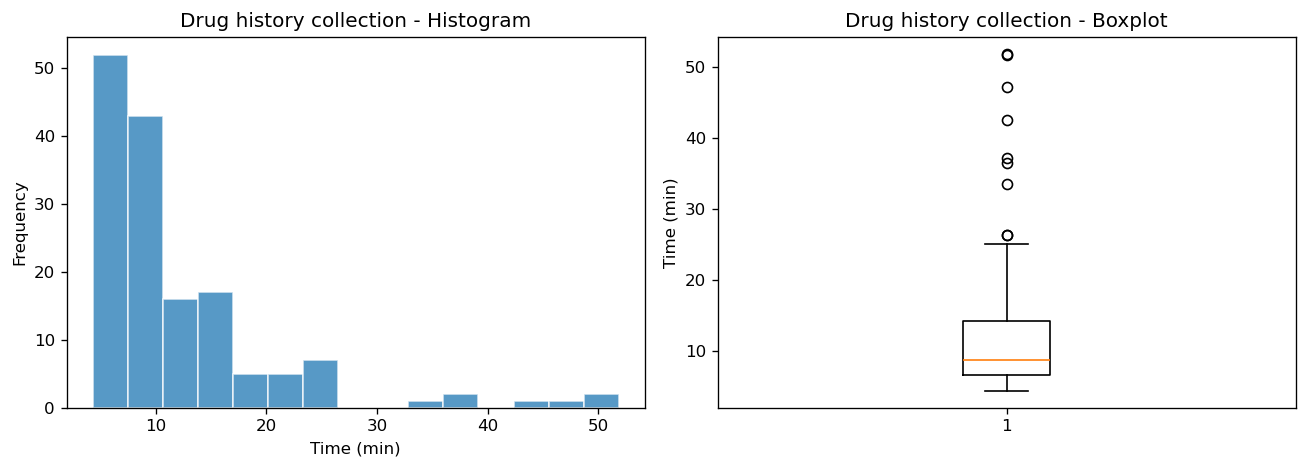

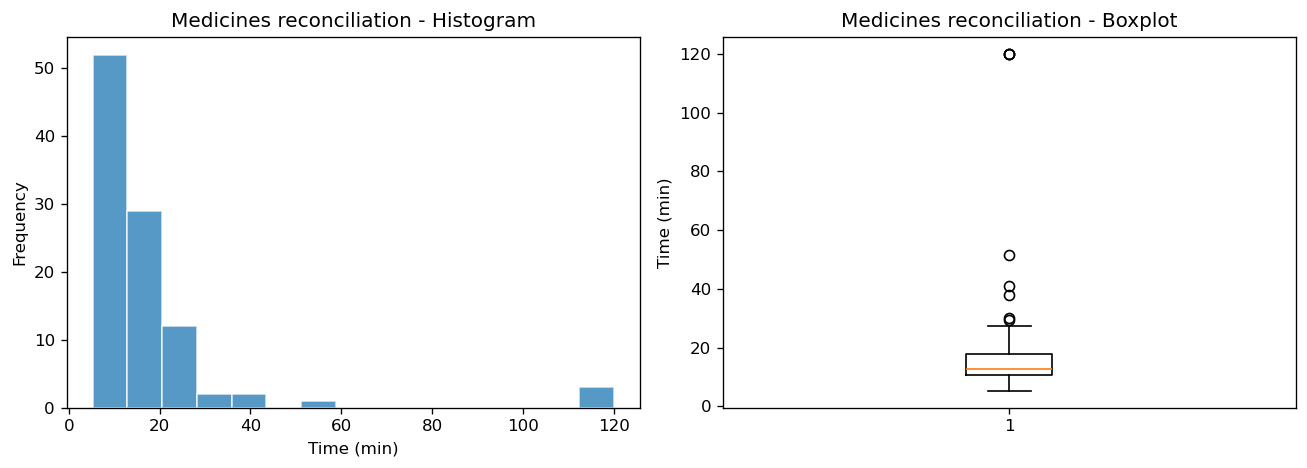

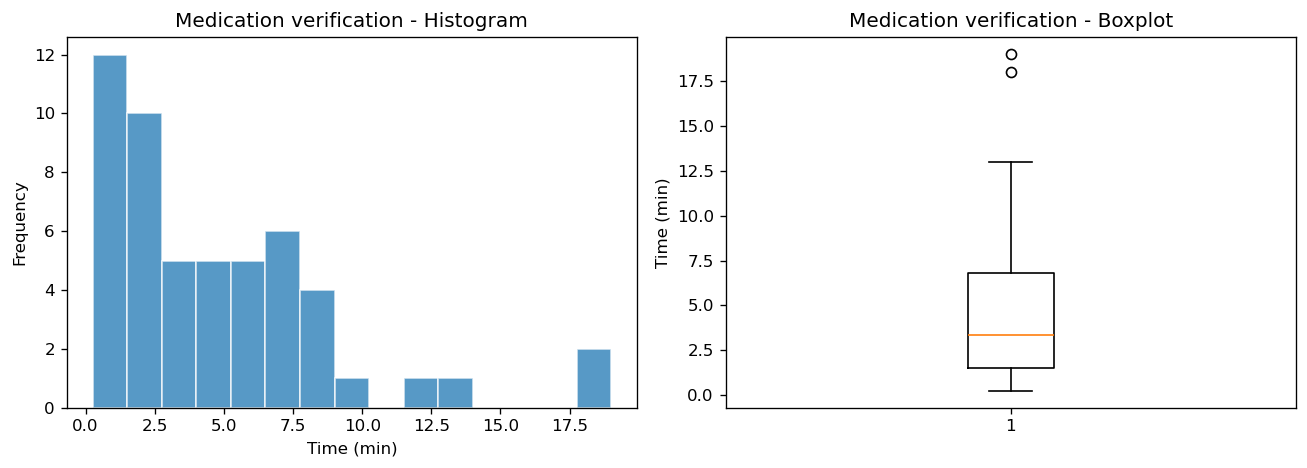

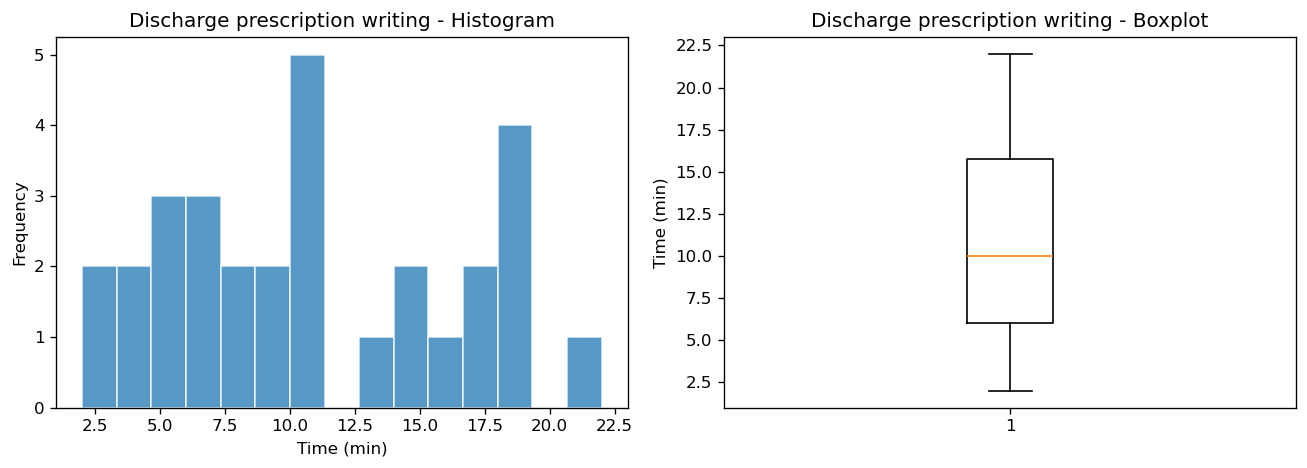

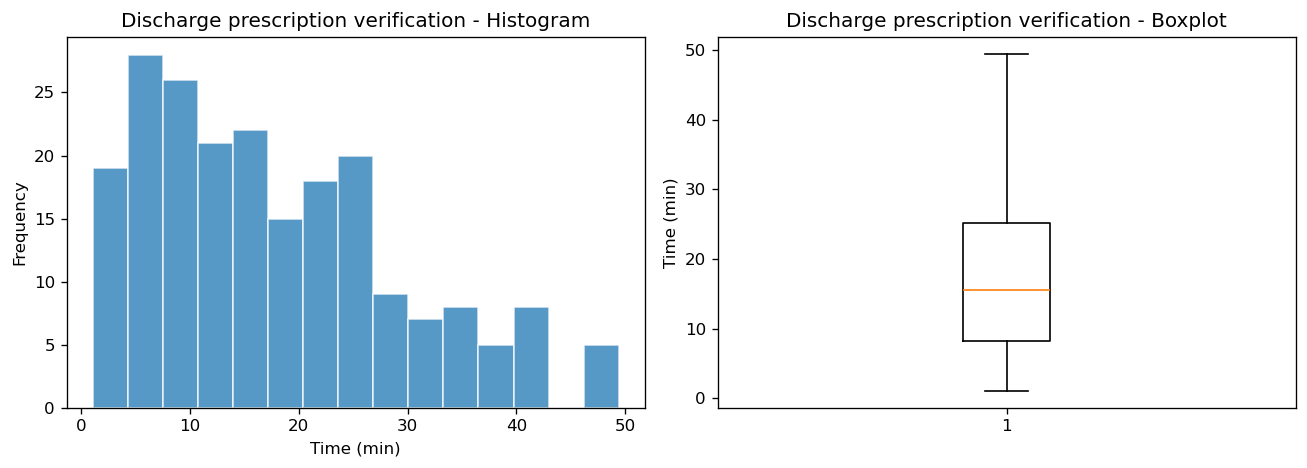

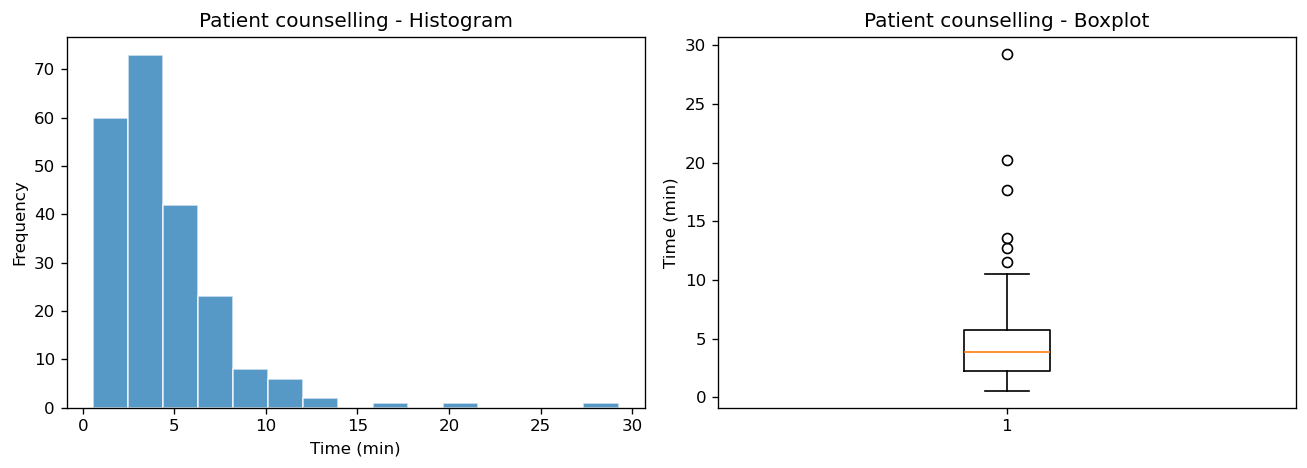

In [130]:
# =========================================================
# 14. Histogram + boxplot by task
#    All activities use case-level time
# =========================================================
def plot_hist_box(df, task_label, value_col="time", bins=15):
    s = df[value_col].dropna().astype(float)
    if len(s) == 0:
        return

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    axes[0].hist(s, bins=bins, edgecolor="white", alpha=0.75)
    axes[0].set_title(f"{task_label} - Histogram")
    axes[0].set_xlabel("Time (min)")
    axes[0].set_ylabel("Frequency")

    axes[1].boxplot(s, vert=True)
    axes[1].set_title(f"{task_label} - Boxplot")
    axes[1].set_ylabel("Time (min)")

    plt.tight_layout()
    plt.show()

for step in task_order:
    if step in ["Patient admission", "Discrepancy resolution"]:
        continue

    df_step = audit.loc[audit["task_label"] == step]
    plot_hist_box(df_step, step)

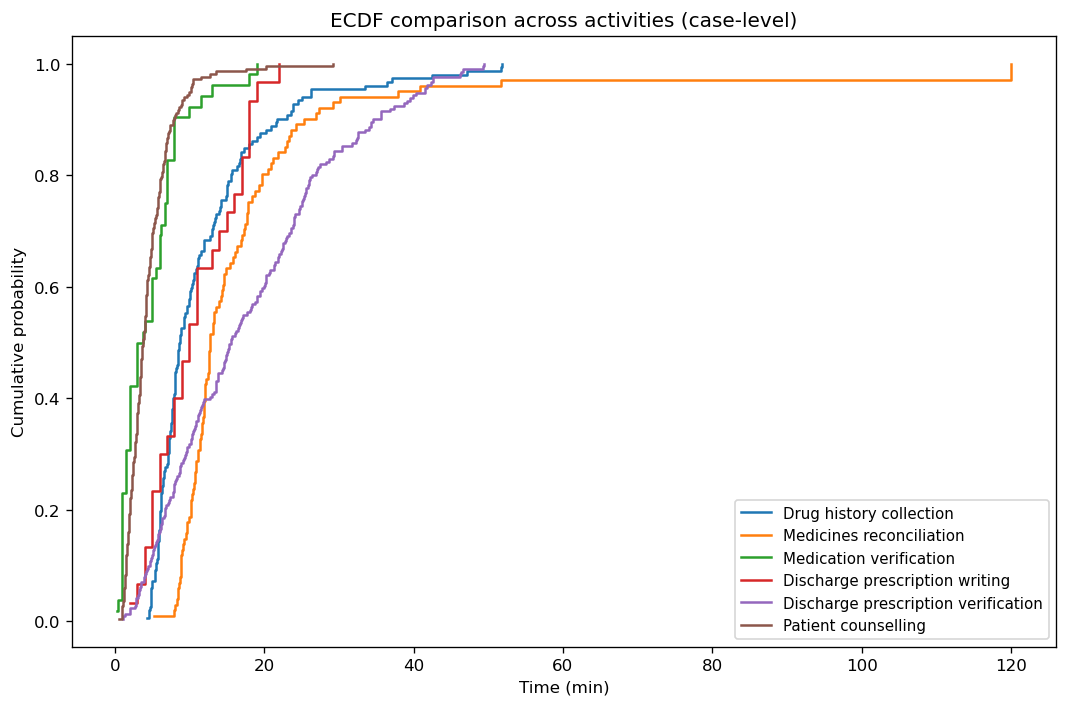

In [133]:
# =========================================================
# 15. ECDF comparison across activities
# =========================================================
def ecdf_values(x):
    x = np.sort(np.asarray(x))
    y = np.arange(1, len(x) + 1) / len(x)
    return x, y

plt.figure(figsize=(9, 6))

for step in task_order:
    if step in ["Patient admission", "Discrepancy resolution"]:
        continue

    s = audit.loc[
        audit["task_label"] == step, "time"
    ].dropna().astype(float)

    if len(s) == 0:
        continue

    x, y = ecdf_values(s)
    plt.step(x, y, where="post", label=step)

plt.xlabel("Time (min)")
plt.ylabel("Cumulative probability")
plt.title("ECDF comparison across activities (case-level)")
plt.legend()
plt.tight_layout()
plt.show()

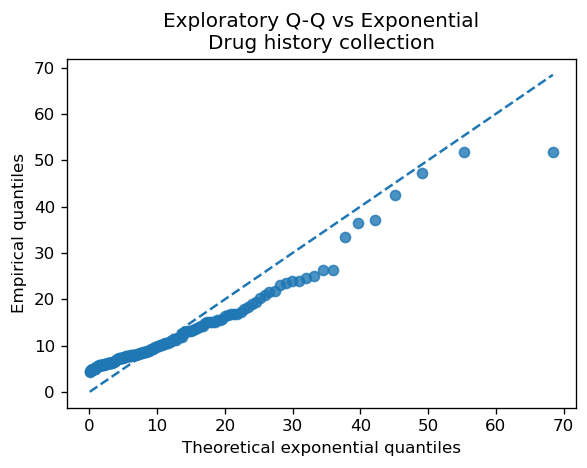

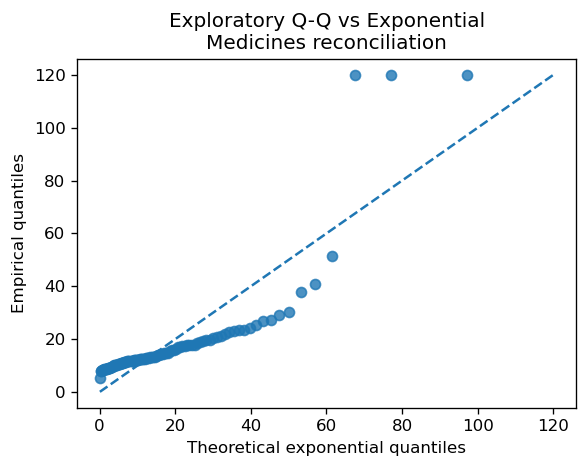

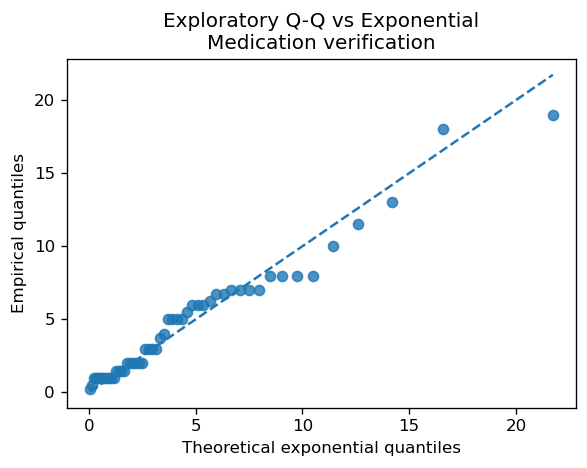

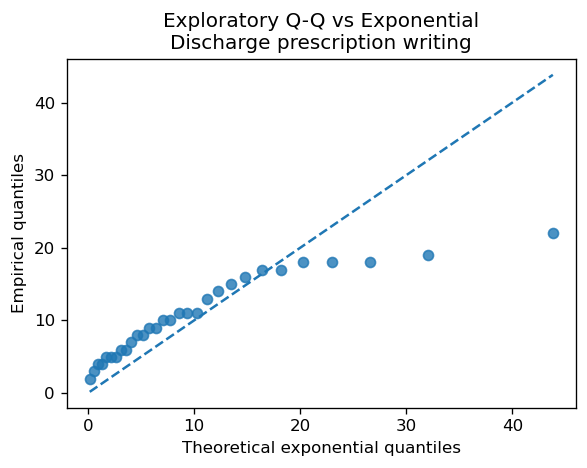

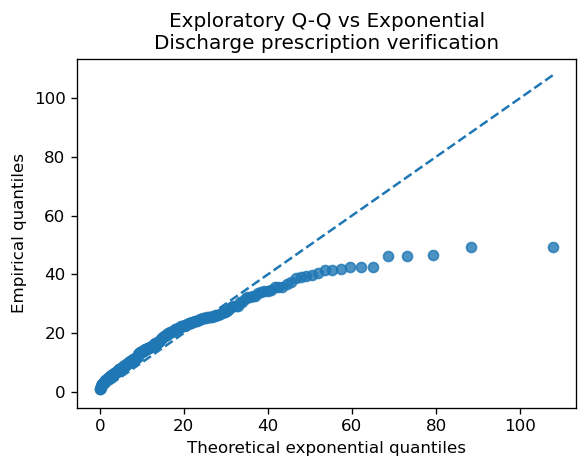

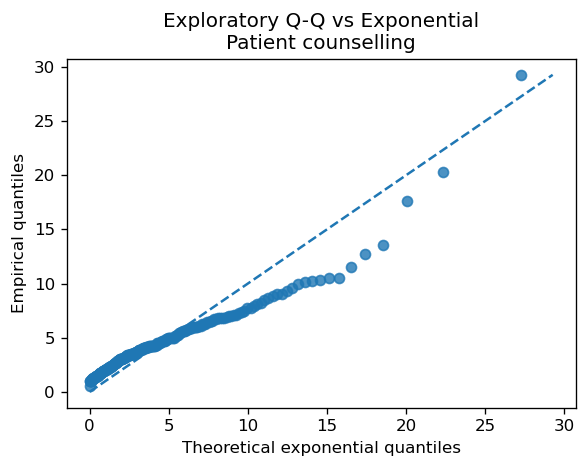

In [135]:
# =========================================================
# 16. Exploratory QQ plot vs exponential
#    Pre-fitting diagnostic only
# =========================================================
def qqplot_exponential(series, title):
    s = pd.Series(series).dropna().astype(float)
    s = np.sort(s.values)
    n = len(s)

    if n < 3:
        print(f"Skipping {title}: too few observations.")
        return

    scale_hat = s.mean()
    probs = (np.arange(1, n + 1) - 0.5) / n
    theo_q = stats.expon.ppf(probs, scale=scale_hat)

    plt.figure(figsize=(5, 4))
    plt.scatter(theo_q, s, alpha=0.8)

    min_v = min(theo_q.min(), s.min())
    max_v = max(theo_q.max(), s.max())
    plt.plot([min_v, max_v], [min_v, max_v], linestyle="--")

    plt.xlabel("Theoretical exponential quantiles")
    plt.ylabel("Empirical quantiles")
    plt.title(f"Exploratory Q-Q vs Exponential\n{title}")
    plt.tight_layout()
    plt.show()

for step in task_order:
    if step in ["Patient admission", "Discrepancy resolution"]:
        continue

    s = audit.loc[audit["task_label"] == step, "time"]
    if len(s.dropna()) > 0:
        qqplot_exponential(s, step)

# distribution fitting

In [142]:
# =========================================================
# 16A. Candidate set and task list
# =========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize
from scipy.special import gamma as gamma_func
import warnings

warnings.filterwarnings("ignore")
np.random.seed(42)

# empirical-data activities only
fit_task_order = [
    "Drug history collection",
    "Medicines reconciliation",
    "Medication verification",
    "Discharge prescription writing",
    "Discharge prescription verification",
    "Patient counselling"
]

# use the same broad candidate set first for consistency
common_candidates = ["expon", "gamma", "lognorm", "weibull", "lognorm3"]

In [144]:
# =========================================================
# 16B. Data helper
# =========================================================
# Assumes:
# - audit exists
# - verification_case exists from previous steps
# If not, rebuild verification_case from audit

if "verification_case" not in globals():
    verification_case = audit.loc[
        audit["task_label"] == "Medication verification"
    ].copy()

def get_task_series(task_label):
    """
    Return positive case-level time data for one task.
    Keep task names exactly aligned with previous EDA.
    """
    if task_label == "Medication verification":
        s = verification_case["time"].dropna().astype(float)
    else:
        s = audit.loc[audit["task_label"] == task_label, "time"].dropna().astype(float)

    s = s[np.isfinite(s)]
    s = s[s > 0]
    return pd.Series(s, name=task_label).reset_index(drop=True)

In [146]:
# =========================================================
# 16C. 3-parameter lognormal fit helper
# =========================================================

def neg_loglik_lognorm3(theta, data):
    mu, sigma, threshold = theta

    if sigma <= 0:
        return np.inf

    # threshold must be below min(data)
    if threshold >= np.min(data):
        return np.inf

    shifted = data - threshold
    if np.any(shifted <= 0):
        return np.inf

    return -np.sum(stats.lognorm.logpdf(shifted, s=sigma, loc=0, scale=np.exp(mu)))


def fit_lognorm3_mle(data):
    data = np.asarray(data, dtype=float)

    # initial guess from ordinary lognormal
    shifted0 = data - (np.min(data) - 0.1)
    shifted0 = np.where(shifted0 <= 0, 1e-6, shifted0)

    sigma0, _, scale0 = stats.lognorm.fit(shifted0, floc=0)
    mu0 = np.log(scale0)
    threshold0 = np.min(data) - 0.1

    result = minimize(
        neg_loglik_lognorm3,
        x0=np.array([mu0, sigma0, threshold0]),
        args=(data,),
        method="Nelder-Mead",
        options={"maxiter": 20000, "xatol": 1e-8, "fatol": 1e-8}
    )

    mu_hat, sigma_hat, threshold_hat = result.x
    loglik = -neg_loglik_lognorm3(result.x, data)

    return {
        "mu_log": mu_hat,
        "sigma_log": sigma_hat,
        "threshold": threshold_hat,
        "loglik": loglik,
        "success": result.success
    }

In [148]:
# =========================================================
# 16D. Fit one candidate
# =========================================================

def fit_one_distribution(data, candidate):
    data = np.asarray(data, dtype=float)
    n = len(data)

    if candidate == "expon":
        loc, scale = stats.expon.fit(data, floc=0)
        params = (0, scale)
        loglik = np.sum(stats.expon.logpdf(data, loc=0, scale=scale))
        k = 1
        dist_obj = stats.expon
        fitted_name = "exponential"
        param_text = f"rate={1/scale:.4f}, mean={scale:.2f}"

    elif candidate == "gamma":
        a, loc, scale = stats.gamma.fit(data, floc=0)
        params = (a, 0, scale)
        loglik = np.sum(stats.gamma.logpdf(data, a=a, loc=0, scale=scale))
        k = 2
        dist_obj = stats.gamma
        fitted_name = "gamma"
        param_text = f"shape={a:.4f}, scale={scale:.4f}, mean={a*scale:.2f}"

    elif candidate == "lognorm":
        s, loc, scale = stats.lognorm.fit(data, floc=0)
        params = (s, 0, scale)
        loglik = np.sum(stats.lognorm.logpdf(data, s=s, loc=0, scale=scale))
        k = 2
        dist_obj = stats.lognorm
        fitted_name = "lognormal"
        mu_log = np.log(scale)
        sigma_log = s
        mean_nat = np.exp(mu_log + sigma_log**2 / 2)
        param_text = f"mu_log={mu_log:.4f}, sigma_log={sigma_log:.4f}, mean={mean_nat:.2f}"

    elif candidate == "weibull":
        c, loc, scale = stats.weibull_min.fit(data, floc=0)
        params = (c, 0, scale)
        loglik = np.sum(stats.weibull_min.logpdf(data, c=c, loc=0, scale=scale))
        k = 2
        dist_obj = stats.weibull_min
        fitted_name = "weibull"
        mean_nat = scale * gamma_func(1 + 1 / c)
        param_text = f"shape={c:.4f}, scale={scale:.4f}, mean={mean_nat:.2f}"

    elif candidate == "lognorm3":
        res = fit_lognorm3_mle(data)
        mu_log = res["mu_log"]
        sigma_log = res["sigma_log"]
        threshold = res["threshold"]
        params = (sigma_log, threshold, np.exp(mu_log))
        loglik = res["loglik"]
        k = 3
        dist_obj = stats.lognorm
        fitted_name = "3-parameter lognormal"
        mean_nat = threshold + np.exp(mu_log + sigma_log**2 / 2)
        param_text = (
            f"mu_log={mu_log:.4f}, sigma_log={sigma_log:.4f}, "
            f"threshold={threshold:.4f}, mean={mean_nat:.2f}"
        )

    else:
        raise ValueError(f"Unsupported candidate: {candidate}")

    aic = 2 * k - 2 * loglik

    # KS
    ks_stat, ks_p = stats.kstest(data, dist_obj.cdf, args=params)

    # AD-style statistic using transformed CDF
    x_sorted = np.sort(data)
    u = np.clip(dist_obj.cdf(x_sorted, *params), 1e-10, 1 - 1e-10)
    i = np.arange(1, n + 1)
    ad_stat = -n - np.mean((2*i - 1) * (np.log(u) + np.log(1 - u[::-1])))

    # upper-tail error
    probs = np.array([0.90, 0.95, 0.99])
    emp_q = np.quantile(data, probs)
    fit_q = dist_obj.ppf(probs, *params)
    tail_error = np.mean(np.abs(fit_q - emp_q) / np.maximum(emp_q, 1e-9))

    return {
        "Candidate": candidate,
        "Label": fitted_name,
        "n": n,
        "AIC": aic,
        "KS_stat": ks_stat,
        "KS_p": ks_p,
        "AD_stat": ad_stat,
        "Tail_error": tail_error,
        "param_text": param_text,
        "dist_obj": dist_obj,
        "params": params
    }

In [150]:
# =========================================================
# 16E. Fit all candidates for one activity
# =========================================================

def fit_activity(task_label, candidate_list=None):
    if candidate_list is None:
        candidate_list = common_candidates

    s = get_task_series(task_label)
    data = s.to_numpy()

    results = []
    for cand in candidate_list:
        try:
            out = fit_one_distribution(data, cand)
            results.append(out)
        except Exception as e:
            results.append({
                "Candidate": cand,
                "Label": cand,
                "n": len(data),
                "AIC": np.nan,
                "KS_stat": np.nan,
                "KS_p": np.nan,
                "AD_stat": np.nan,
                "Tail_error": np.nan,
                "param_text": f"fit failed: {e}",
                "dist_obj": None,
                "params": None
            })

    fit_df = pd.DataFrame(results)

    # selection rule:
    # 1) prefer KS_p >= .05
    # 2) then lowest AIC
    # 3) then lower tail error
    usable = fit_df.dropna(subset=["AIC", "KS_p", "Tail_error"]).copy()
    usable["KS_pass"] = usable["KS_p"] >= 0.05

    if usable["KS_pass"].any():
        best_row = usable.loc[usable["KS_pass"]].sort_values(
            ["AIC", "Tail_error", "AD_stat"],
            ascending=[True, True, True]
        ).iloc[0]
    else:
        best_row = usable.sort_values(
            ["AIC", "Tail_error", "AD_stat"],
            ascending=[True, True, True]
        ).iloc[0]

    return s, fit_df.sort_values("AIC"), best_row["Candidate"]

In [234]:
def plot_activity_fits(task_label, candidate_list=None, bins=15):
    s, fit_df, best_candidate = fit_activity(task_label, candidate_list=candidate_list)
    data = s.to_numpy()

    # Filter candidates with valid fit results
    plot_df = fit_df.dropna(subset=["dist_obj", "params"]).copy()
    n_candidates = len(plot_df)

    # ---------------------------------------------------------
    # Grid Layout: 3 rows x 4 columns
    # Row 0: Density and CDF (2 columns each, equal width)
    # Row 1-2: QQ Plots (1 column each, up to 4 per row)
    # ---------------------------------------------------------
    fig = plt.figure(figsize=(16, 14))
    gs = fig.add_gridspec(3, 4)

    # Top row: Density and CDF with equal width (2 columns each)
    ax_dens = fig.add_subplot(gs[0, 0:2])
    ax_cdf = fig.add_subplot(gs[0, 2:4])

    # Bottom rows: Individual slots for QQ plots
    qq_axes = [
        fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1]), 
        fig.add_subplot(gs[1, 2]), fig.add_subplot(gs[1, 3]),
        fig.add_subplot(gs[2, 0]), fig.add_subplot(gs[2, 1]), 
        fig.add_subplot(gs[2, 2]), fig.add_subplot(gs[2, 3])
    ]

    # -------------------------
    # 1. Density Comparison
    # -------------------------
    ax_dens.hist(data, bins=bins, density=True, alpha=0.3, color="gray", label="Data")
    x_grid = np.linspace(max(1e-6, data.min() * 0.8), data.max() * 1.1, 500)

    for _, row in plot_df.iterrows():
        y_pdf = row["dist_obj"].pdf(x_grid, *row["params"])
        is_best = (row["Candidate"] == best_candidate)
        ax_dens.plot(x_grid, y_pdf, linewidth=2.5 if is_best else 1.5, 
                     label=f"{row['Label']}{' *' if is_best else ''}")
    
    ax_dens.set_title("Density Comparison", fontsize=12)
    ax_dens.legend(fontsize=9)

    # -------------------------
    # 2. CDF Comparison
    # -------------------------
    x_sorted = np.sort(data)
    y_ecdf = np.arange(1, len(data) + 1) / len(data)
    ax_cdf.step(x_sorted, y_ecdf, where="post", color="black", label="Empirical", linewidth=1.5)

    for _, row in plot_df.iterrows():
        y_cdf = row["dist_obj"].cdf(x_grid, *row["params"])
        is_best = (row["Candidate"] == best_candidate)
        ax_cdf.plot(x_grid, y_cdf, linewidth=2.2 if is_best else 1.2, 
                    label=f"{row['Label']}{' *' if is_best else ''}")

    ax_cdf.set_title("CDF Comparison", fontsize=12)
    ax_cdf.legend(fontsize=9)

    # -------------------------
    # 3. QQ Plots (Supports up to 5+ candidates)
    # -------------------------
    for i, (idx, row) in enumerate(plot_df.iterrows()):
        ax = qq_axes[i]
        theo, samp = qq_points(data, row["dist_obj"], row["params"])

        ax.scatter(theo, samp, s=10, alpha=0.6, color='steelblue')
        
        # Reference Line (y=x)
        all_val = np.concatenate([theo, samp])
        lim_min, lim_max = all_val.min(), all_val.max()
        ax.plot([lim_min, lim_max], [lim_min, lim_max], "r--", lw=1)

        is_best = (row["Candidate"] == best_candidate)
        ax.set_title(f"QQ Plot: {row['Label']}{' *' if is_best else ''}", fontsize=10)
        ax.set_xlabel("Theoretical Quantiles", fontsize=8)
        ax.set_ylabel("Sample Quantiles", fontsize=8)

    # Hide unused axes in the QQ plot grid
    for j in range(i + 1, len(qq_axes)):
        qq_axes[j].axis('off')

    plt.suptitle(f"Distribution Fitting Analysis: {task_label}", fontsize=16, y=1.02)
    plt.tight_layout()
    plt.show()

    display_cols = ["Candidate", "AIC", "KS_p", "AD_stat", "Tail_error", "param_text"]
    result_table = fit_df[display_cols].sort_values(["AIC", "Tail_error"])

    print(f"\nBest candidate for {task_label}: {best_candidate}")

    return result_table, best_candidate

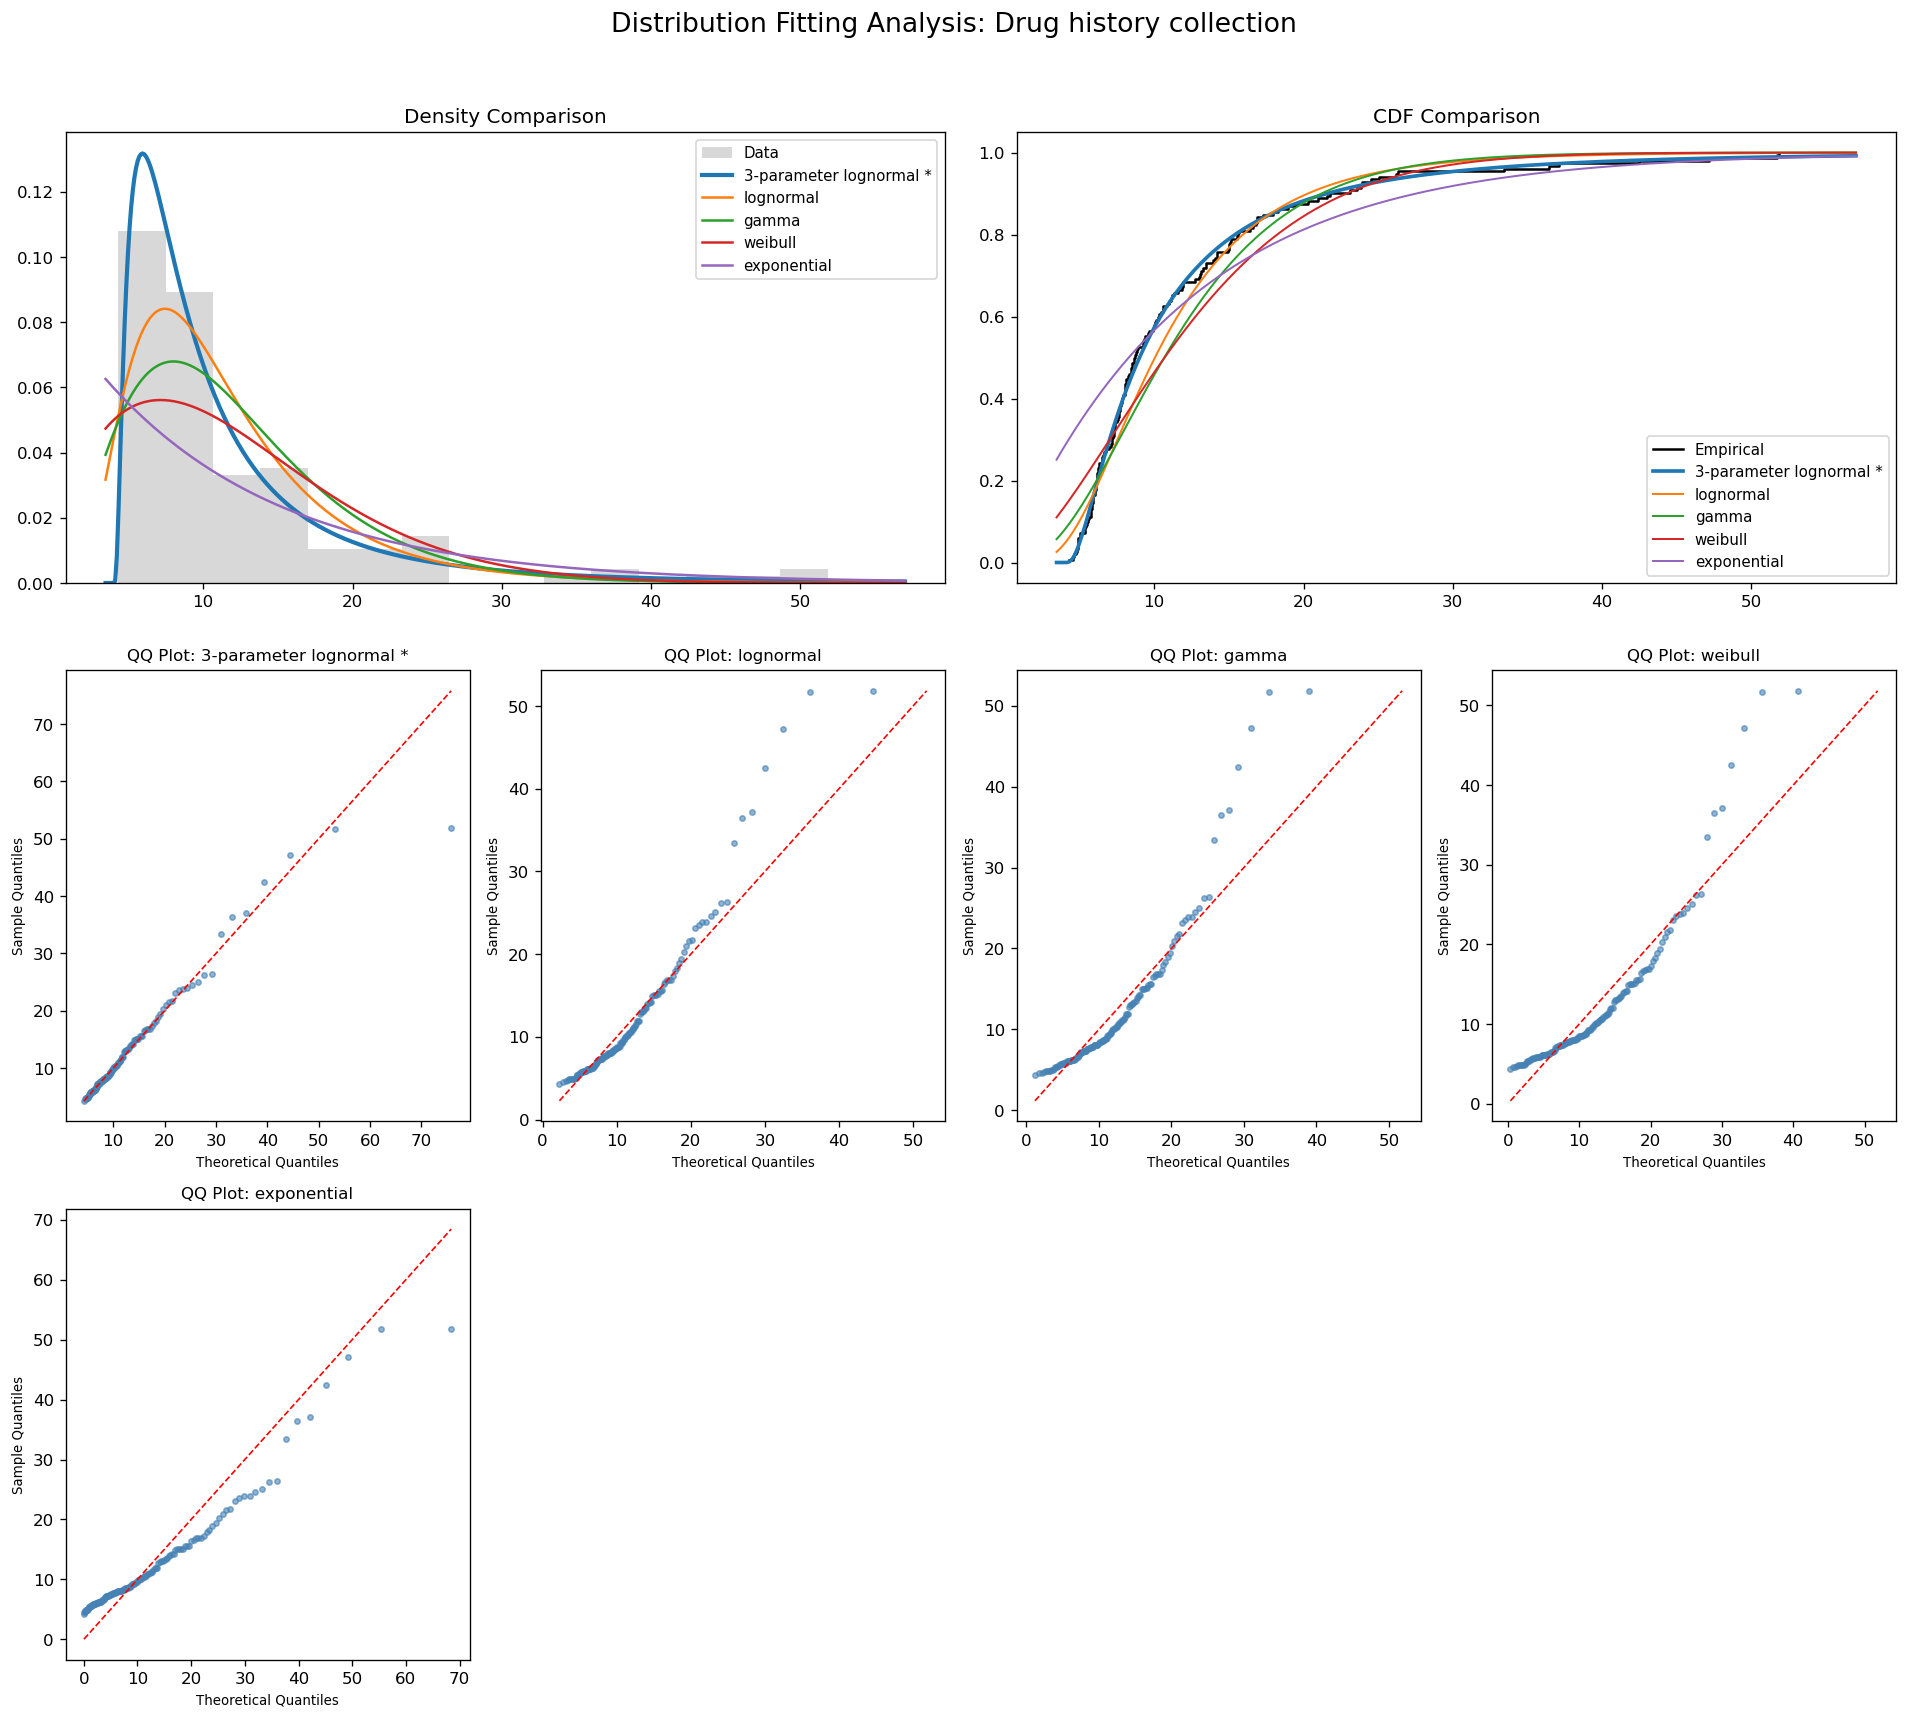


Best candidate for Drug history collection: lognorm3


(  Candidate          AIC          KS_p    AD_stat  Tail_error  \
 4  lognorm3   920.329100  9.887750e-01   0.196439    0.061950   
 2   lognorm   954.287423  3.845354e-02   2.637043    0.131551   
 1     gamma   985.660596  4.802274e-03   5.034050    0.130918   
 3   weibull  1012.164222  8.287494e-04   6.812855    0.121091   
 0     expon  1060.587171  1.706069e-13  16.213571    0.249252   
 
                                           param_text  
 4  mu_log=1.6082, sigma_log=0.9807, threshold=4.0...  
 2        mu_log=2.3074, sigma_log=0.5486, mean=11.68  
 1             shape=3.0164, scale=3.9675, mean=11.97  
 3            shape=1.5778, scale=13.4918, mean=12.11  
 0                            rate=0.0836, mean=11.97  ,
 'lognorm3')

In [236]:
# =========================================================
# 16G. Run one activity at a time
# =========================================================

drug_history_fit = plot_activity_fits("Drug history collection")
drug_history_fit

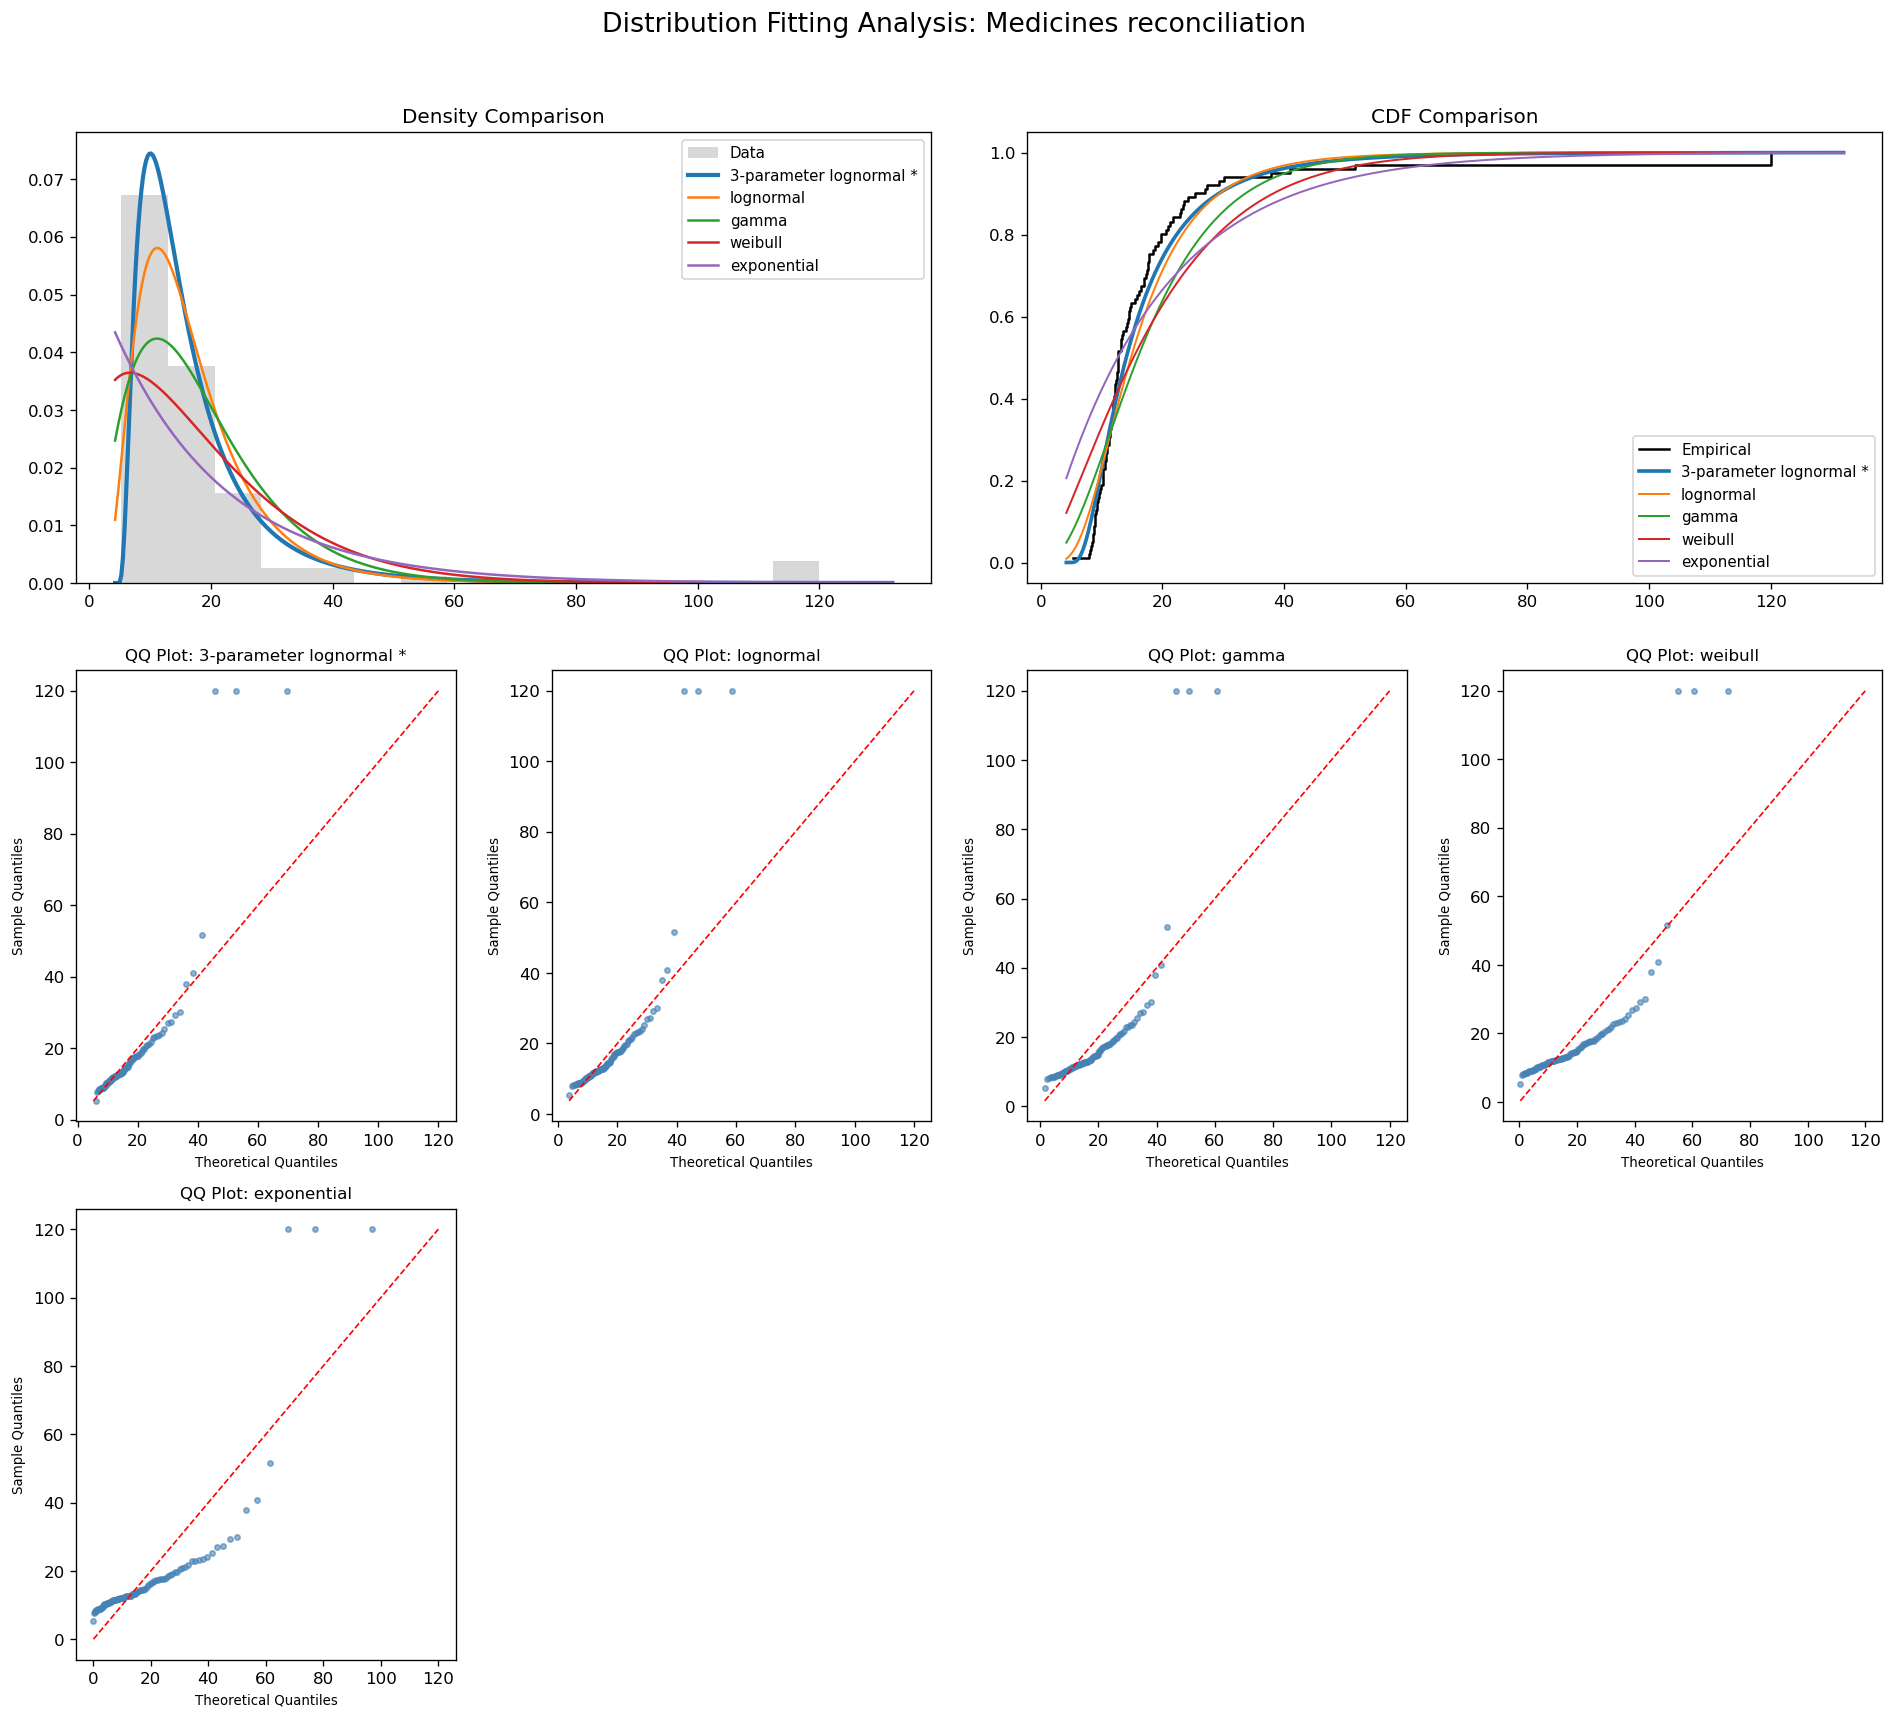


Best candidate for Medicines reconciliation: lognorm3


(  Candidate         AIC          KS_p    AD_stat  Tail_error  \
 4  lognorm3  687.919016  2.642155e-01   1.843228    0.231079   
 2   lognorm  708.677352  4.598759e-02   3.725629    0.263456   
 1     gamma  754.106103  1.793326e-03   7.790661    0.310750   
 3   weibull  778.004729  9.304032e-06  10.333928    0.399510   
 0     expon  791.004855  6.468527e-11  14.058788    0.467802   
 
                                           param_text  
 4  mu_log=2.2496, sigma_log=0.7463, threshold=4.5...  
 2        mu_log=2.6969, sigma_log=0.5340, mean=17.11  
 1             shape=2.5461, scale=7.1807, mean=18.28  
 3            shape=1.3065, scale=20.1802, mean=18.62  
 0                            rate=0.0547, mean=18.28  ,
 'lognorm3')

In [238]:
med_recon_fit = plot_activity_fits("Medicines reconciliation")
med_recon_fit

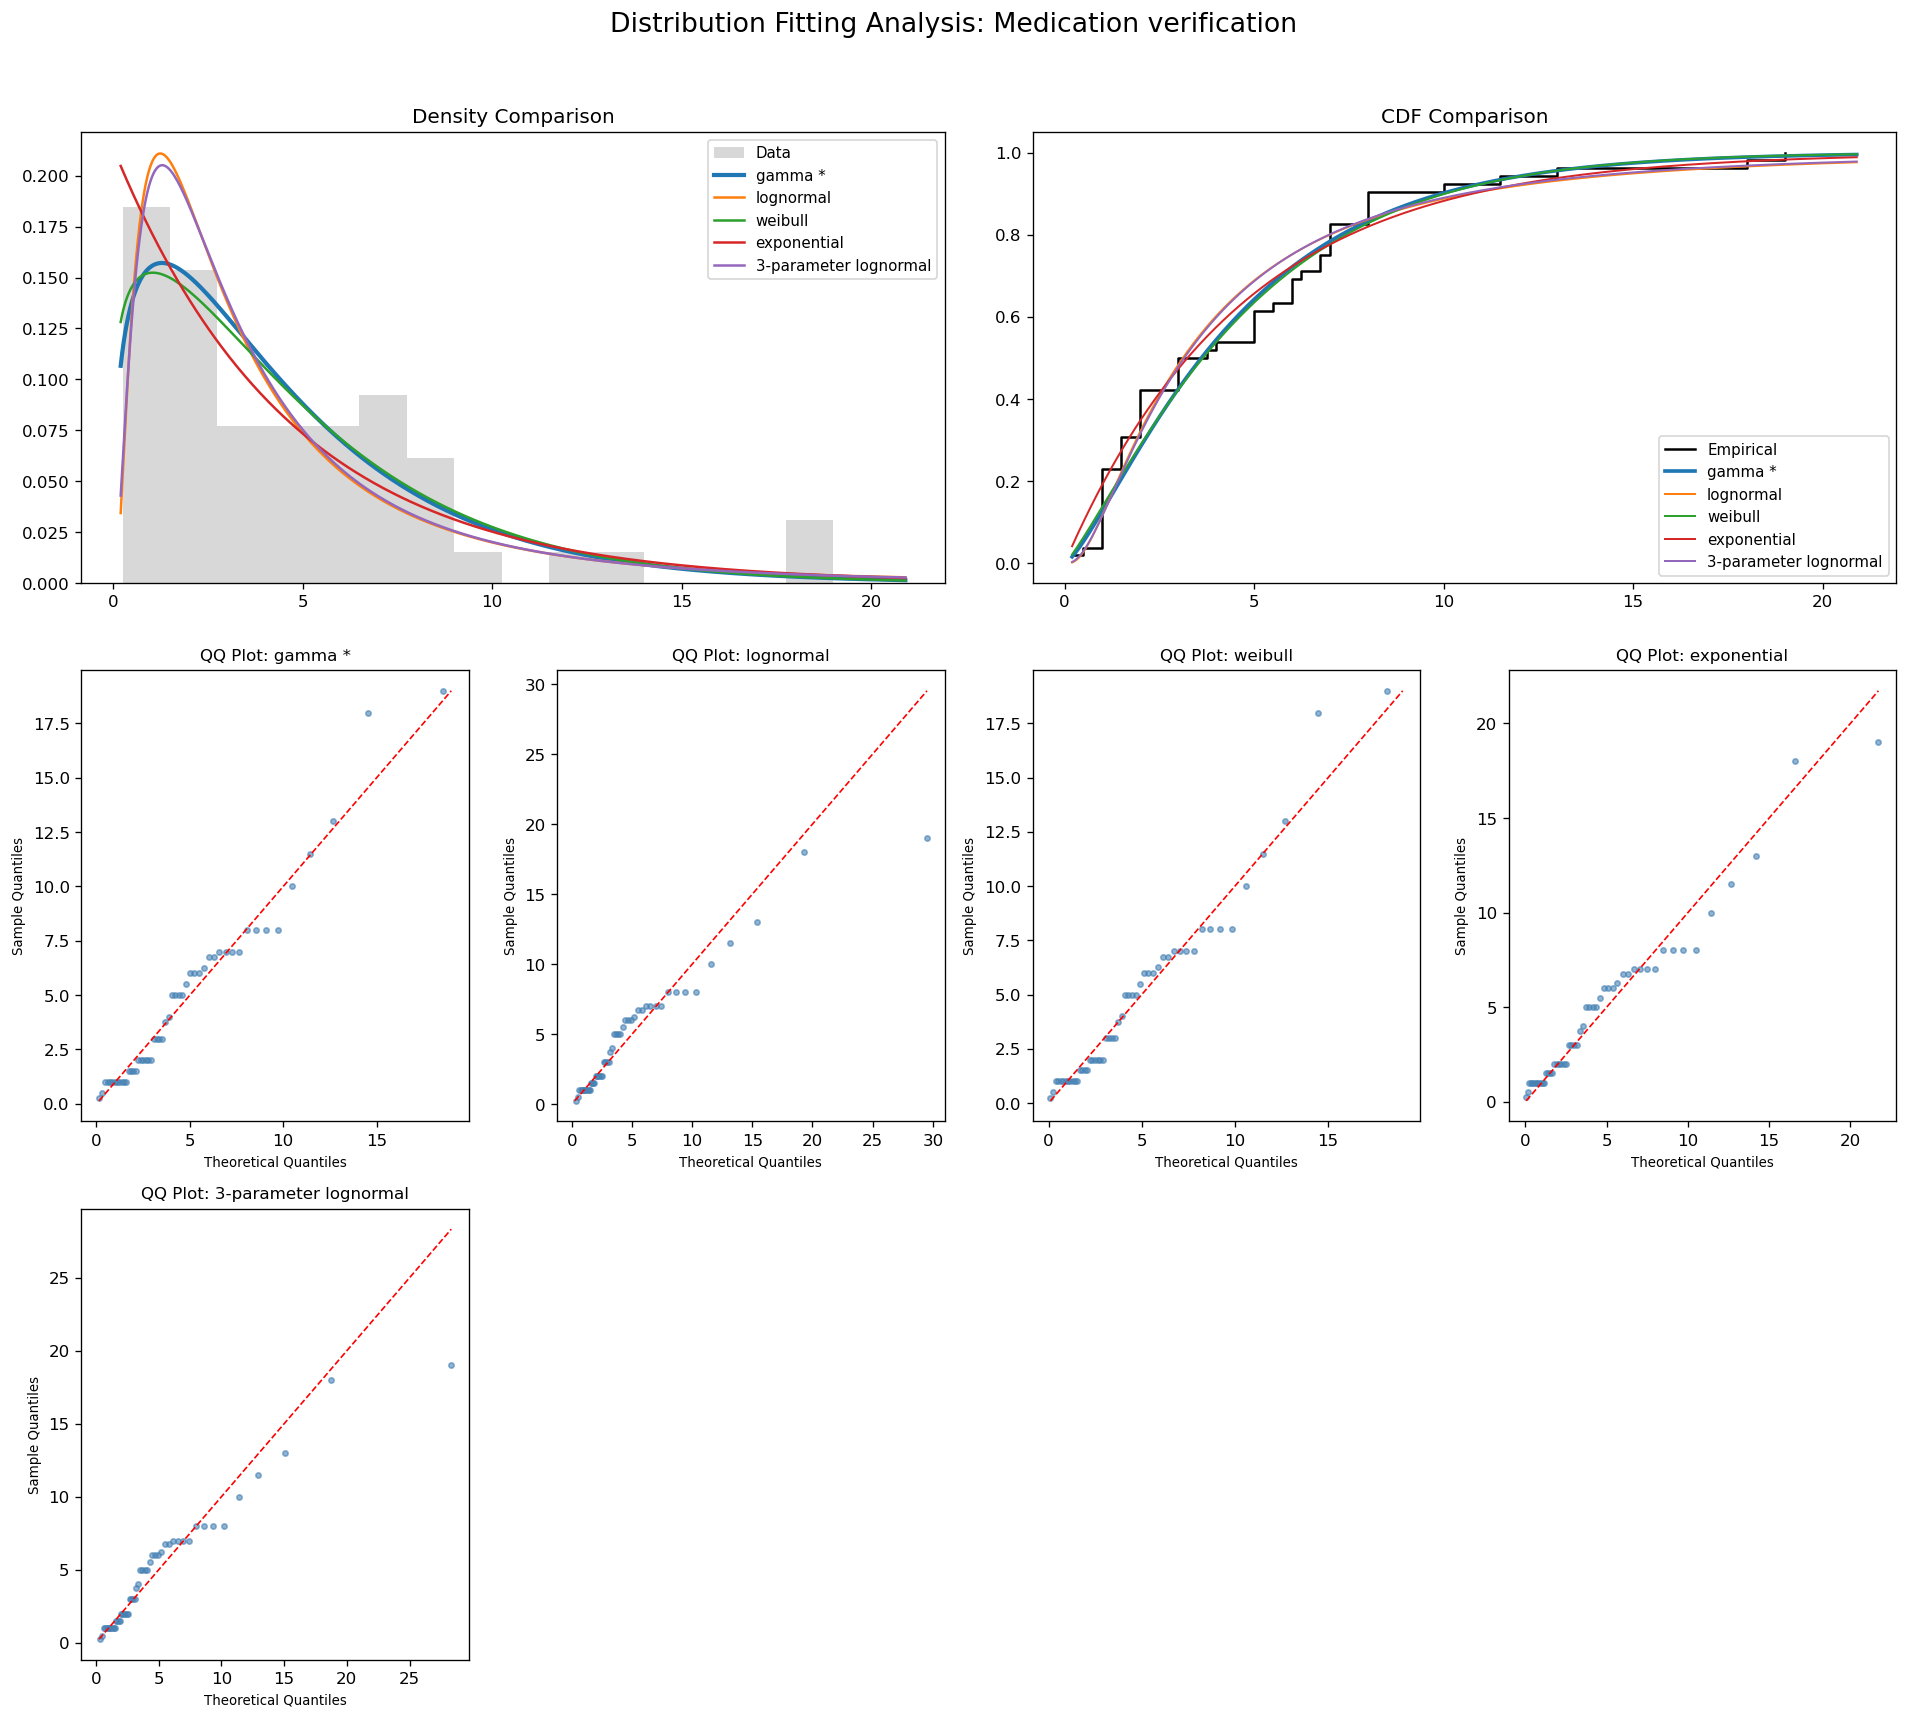


Best candidate for Medication verification: gamma


(  Candidate         AIC      KS_p   AD_stat  Tail_error  \
 1     gamma  265.426531  0.237491  0.923124    0.092596   
 2   lognorm  265.694536  0.175735  1.068290    0.383853   
 3   weibull  266.090811  0.271493  0.874091    0.103799   
 0     expon  266.455984  0.152654  1.061197    0.220837   
 4  lognorm3  267.631858  0.184476  1.070735    0.347929   
 
                                           param_text  
 1              shape=1.3805, scale=3.3885, mean=4.68  
 2         mu_log=1.1388, sigma_log=0.9594, mean=4.95  
 3              shape=1.1863, scale=4.9740, mean=4.69  
 0                             rate=0.2138, mean=4.68  
 4  mu_log=1.1699, sigma_log=0.9294, threshold=-0....  ,
 'gamma')

In [239]:
med_verif_fit = plot_activity_fits("Medication verification")
med_verif_fit

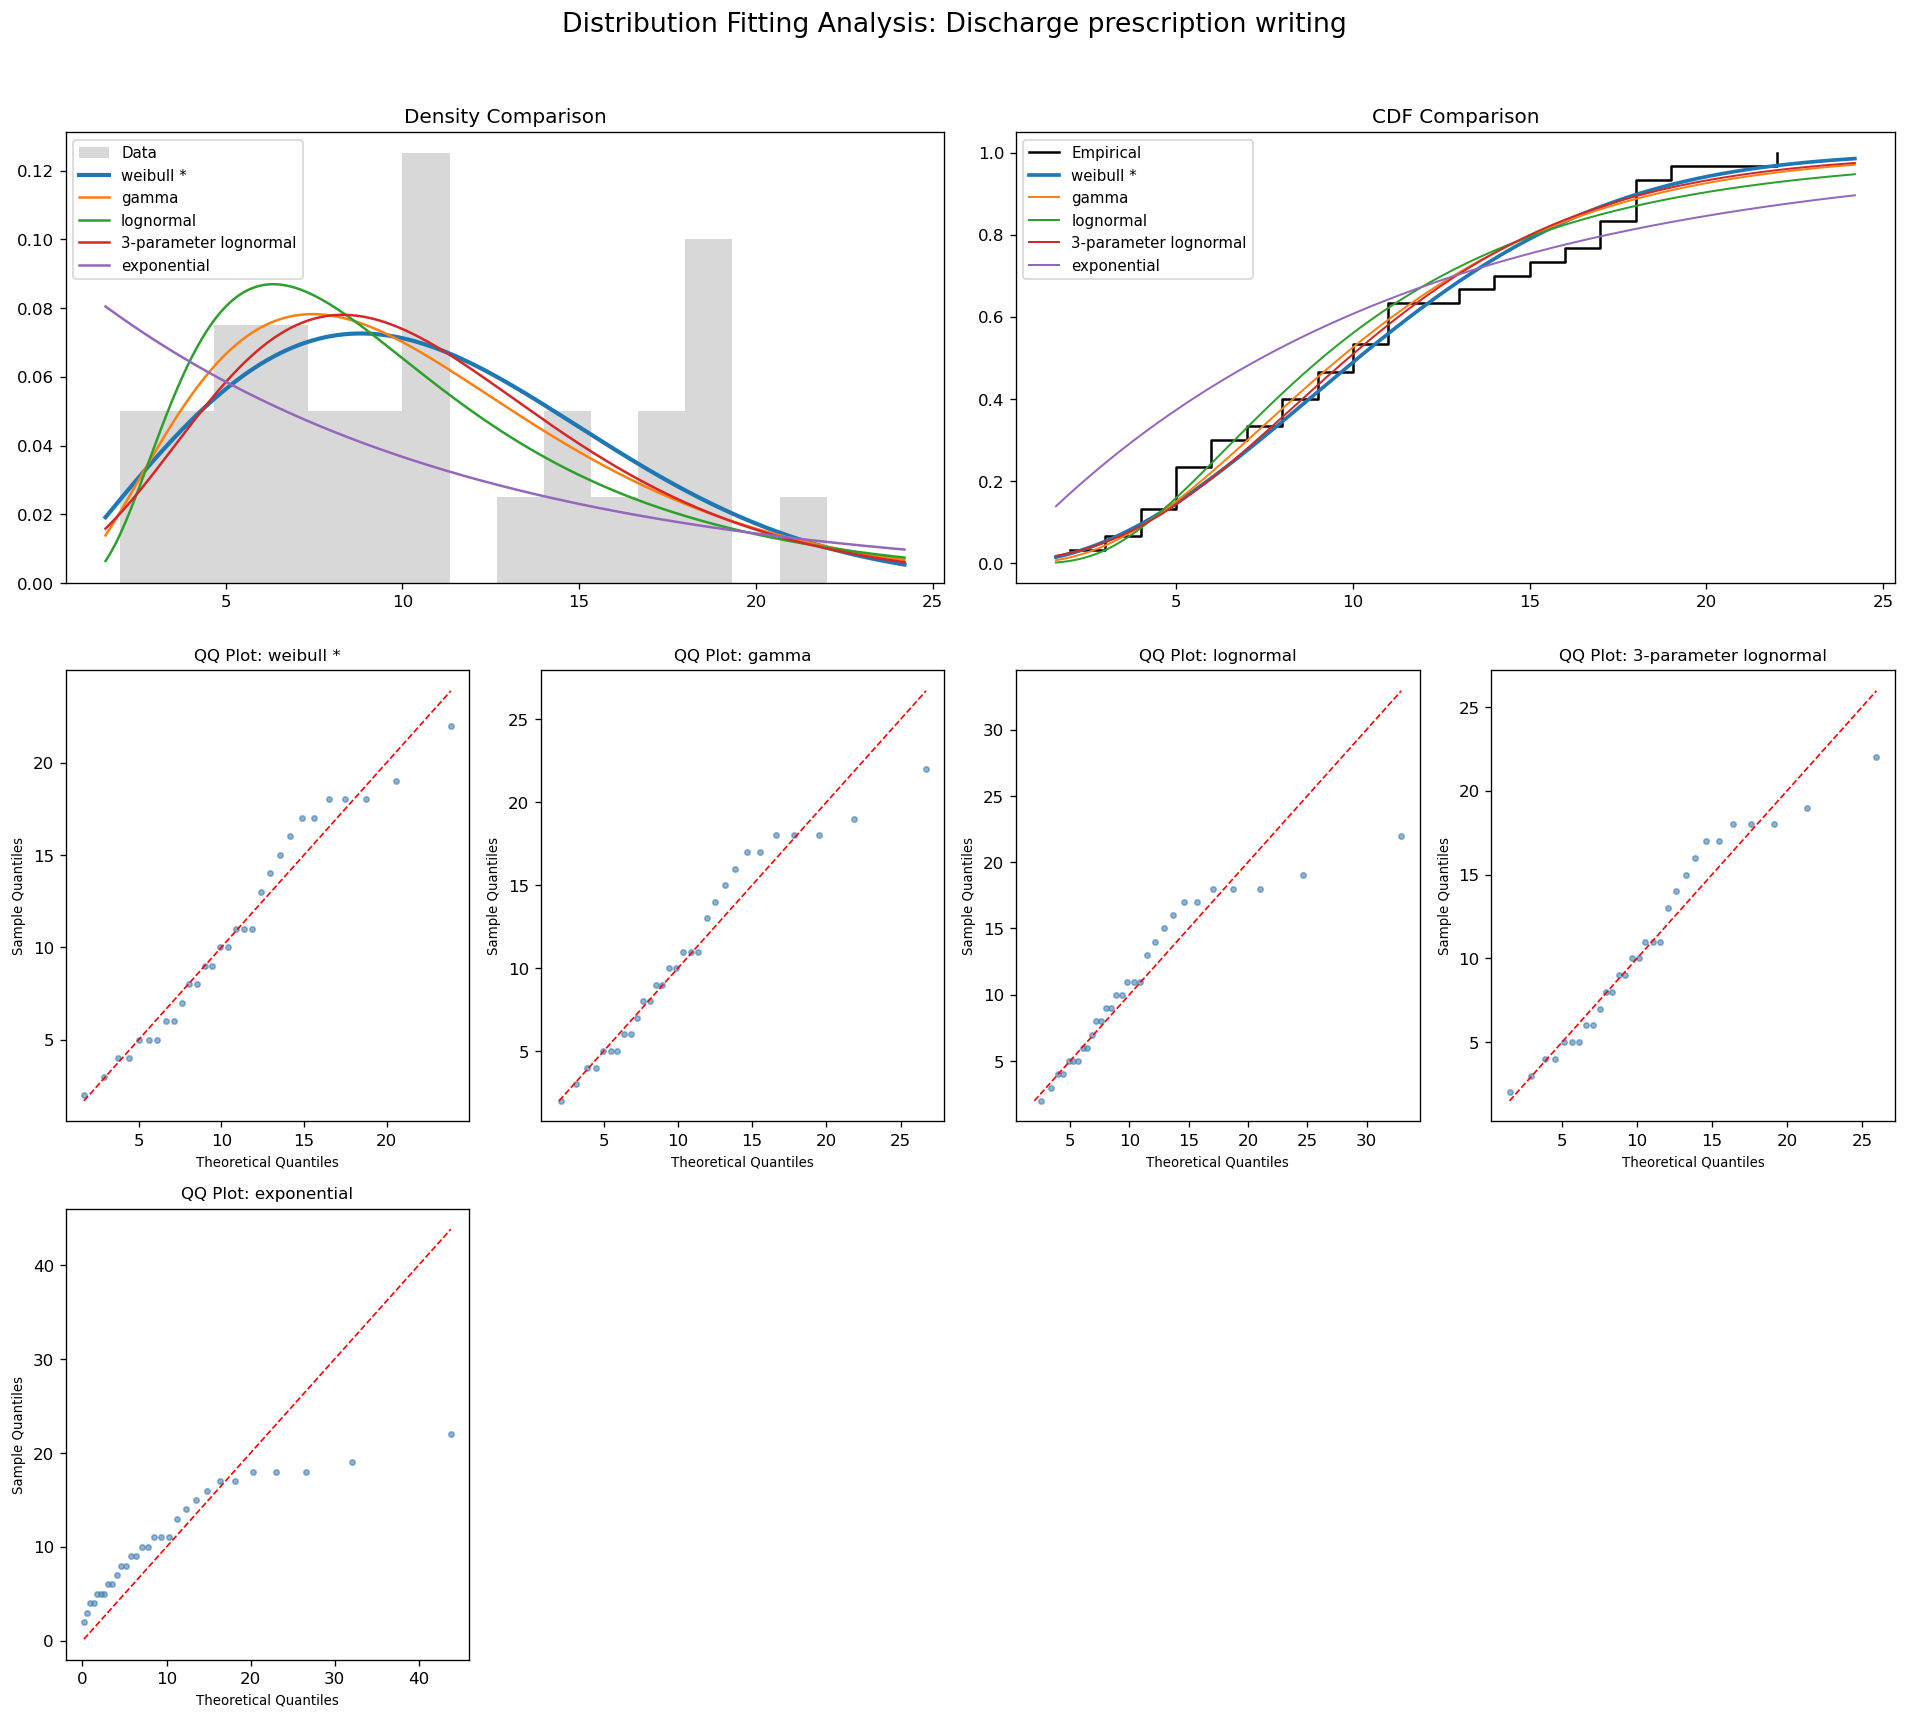


Best candidate for Discharge prescription writing: weibull


(  Candidate         AIC      KS_p   AD_stat  Tail_error  \
 3   weibull  188.081055  0.889799  0.385246    0.102988   
 1     gamma  189.010561  0.905500  0.391272    0.192990   
 2   lognorm  191.448766  0.925332  0.512294    0.393488   
 4  lognorm3  191.854143  0.875266  0.430539    0.164821   
 0     expon  204.214624  0.044887  2.930071    0.809588   
 
                                           param_text  
 3            shape=2.0757, scale=12.1095, mean=10.73  
 1             shape=3.2984, scale=3.2440, mean=10.70  
 2        mu_log=2.2111, sigma_log=0.6030, mean=10.94  
 4  mu_log=2.8605, sigma_log=0.3067, threshold=-7....  
 0                            rate=0.0935, mean=10.70  ,
 'weibull')

In [240]:
discharge_write_fit = plot_activity_fits("Discharge prescription writing")
discharge_write_fit

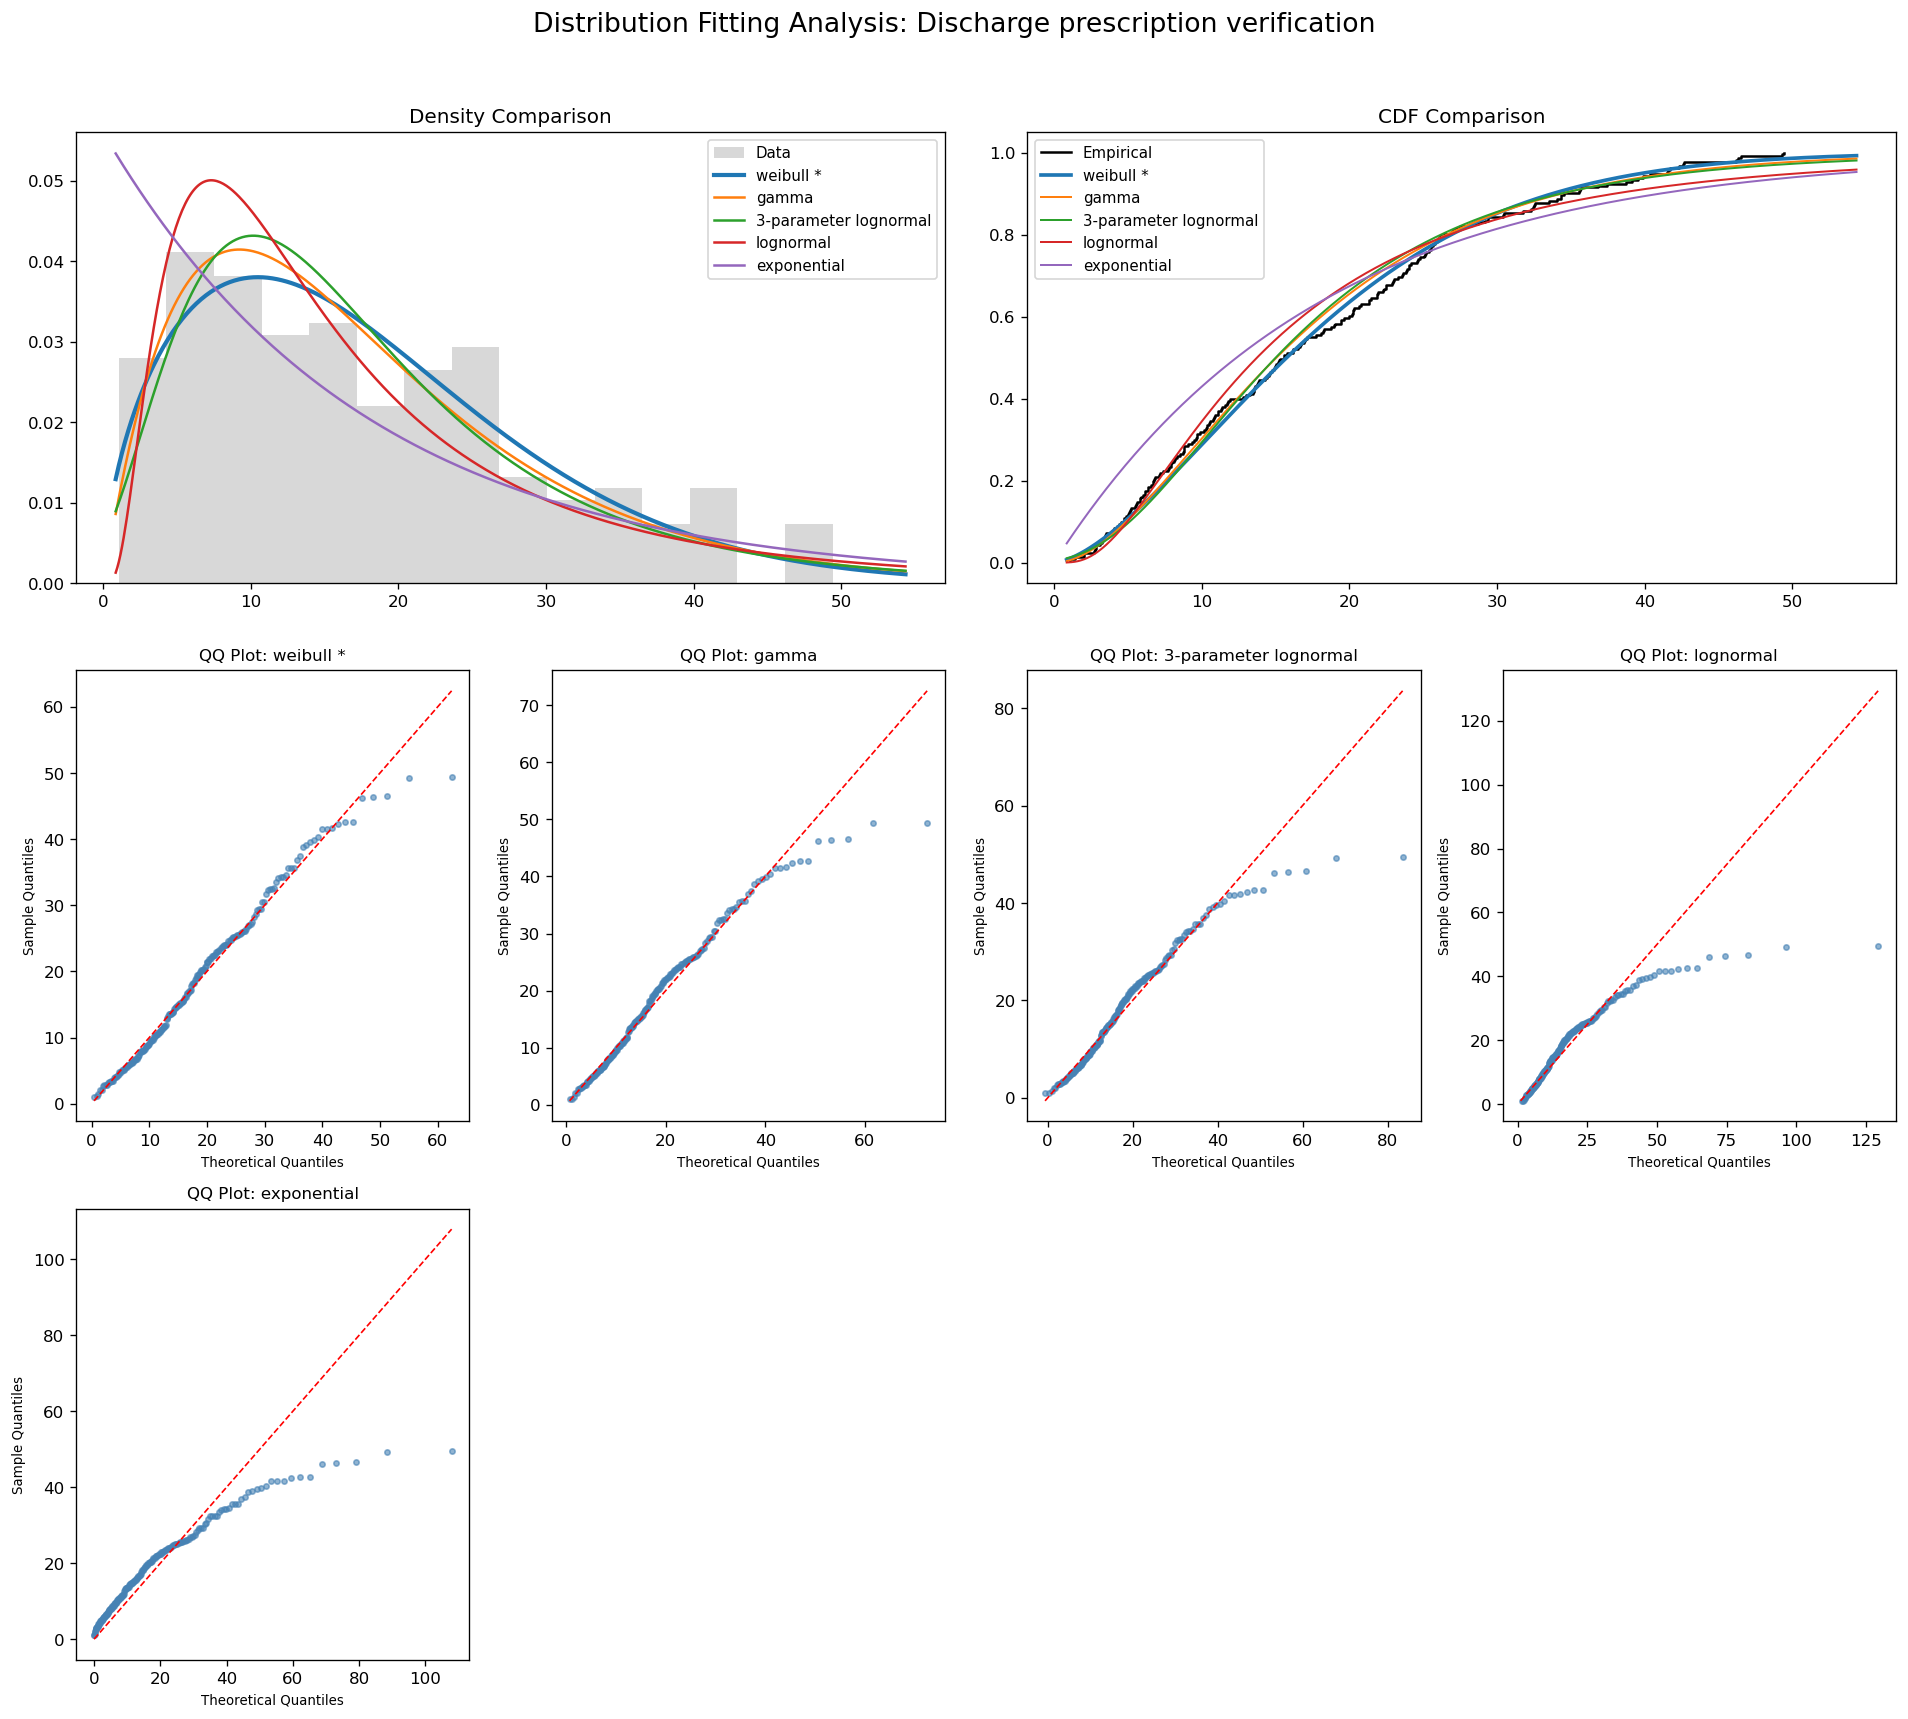


Best candidate for Discharge prescription verification: weibull


(  Candidate          AIC      KS_p   AD_stat  Tail_error  \
 3   weibull  1585.991729  0.829177  0.586693    0.058361   
 1     gamma  1588.874258  0.426573  0.769083    0.093301   
 4  lognorm3  1600.831563  0.272973  1.225880    0.134932   
 2   lognorm  1611.421138  0.085366  2.287152    0.403647   
 0     expon  1640.124800  0.000944  9.378230    0.419978   
 
                                           param_text  
 3            shape=1.5738, scale=19.8954, mean=17.87  
 1             shape=2.0709, scale=8.6176, mean=17.85  
 4  mu_log=3.0077, sigma_log=0.5234, threshold=-5....  
 2        mu_log=2.6214, sigma_log=0.7935, mean=18.84  
 0                            rate=0.0560, mean=17.85  ,
 'weibull')

In [241]:
discharge_verif_fit = plot_activity_fits("Discharge prescription verification")
discharge_verif_fit

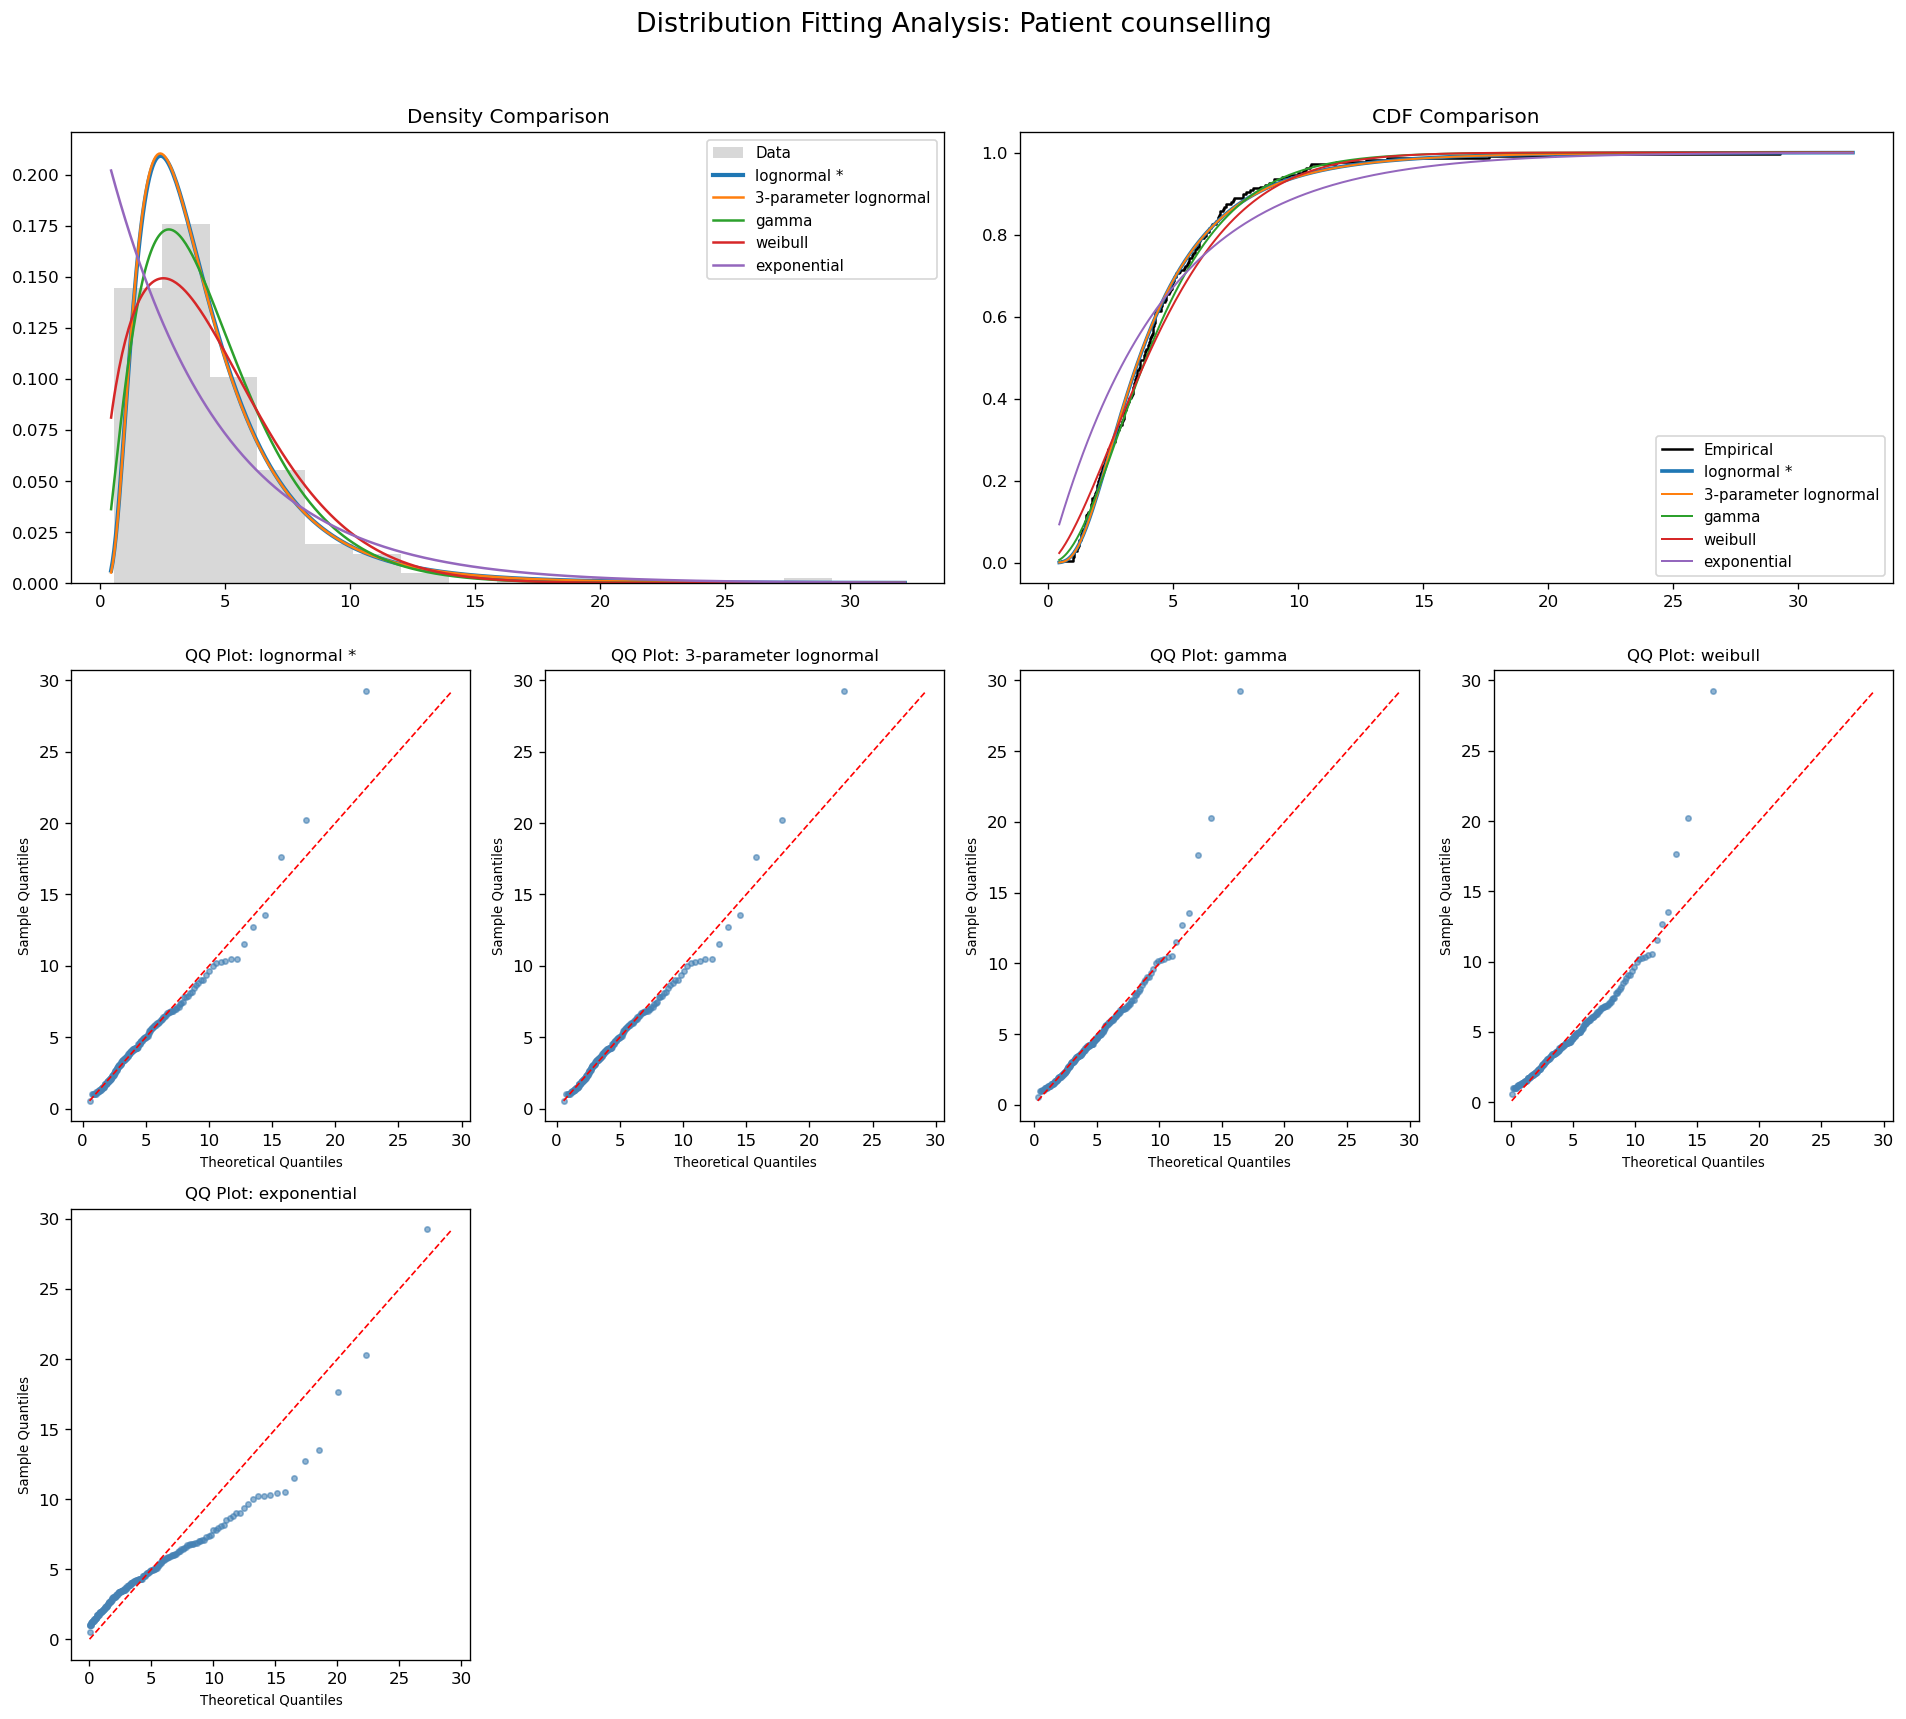


Best candidate for Patient counselling: lognorm


(  Candidate          AIC          KS_p    AD_stat  Tail_error  \
 2   lognorm   989.036781  7.831269e-01   0.435123    0.049443   
 4  lognorm3   991.016321  7.471407e-01   0.455683    0.049004   
 1     gamma  1004.096115  5.414013e-01   0.766862    0.094156   
 3   weibull  1027.035949  1.446146e-01   2.401536    0.109029   
 0     expon  1087.572385  3.156358e-08  15.799600    0.291509   
 
                                           param_text  
 2         mu_log=1.2951, sigma_log=0.6412, mean=4.48  
 4  mu_log=1.2826, sigma_log=0.6493, threshold=0.0...  
 1              shape=2.5788, scale=1.7402, mean=4.49  
 3              shape=1.5350, scale=5.0265, mean=4.53  
 0                             rate=0.2228, mean=4.49  ,
 'lognorm')

In [242]:
patient_counselling_fit = plot_activity_fits("Patient counselling")
patient_counselling_fit

In [253]:
# =========================================================
# 16H. Run all activities and collect summary table
# =========================================================

all_fit_tables = {}
best_fit_summary = []

for task_label in fit_task_order:
    s, fit_df, best_candidate = fit_activity(task_label, candidate_list=common_candidates)
    all_fit_tables[task_label] = fit_df.copy()

    best_row = fit_df.loc[fit_df["Candidate"] == best_candidate].iloc[0]

    best_fit_summary.append({
        "task_label": task_label,
        "n": best_row["n"],
        "best_distribution": best_row["Candidate"],
        "AIC": best_row["AIC"],
        "KS_p": best_row["KS_p"],
        "AD_stat": best_row["AD_stat"],
        "Tail_error": best_row["Tail_error"],
        "parameter_values": best_row["param_text"]
    })

best_fit_summary = pd.DataFrame(best_fit_summary)
best_fit_summary

,task_label,n,best_distribution,AIC,KS_p,AD_stat,Tail_error,parameter_values
0,Drug history collection,152,lognorm3,920.329100,0.988775,0.196439,0.061950,"mu_log=1.6082, sigma_log=0.9807, threshold=4.0..."
1,Medicines reconciliation,101,lognorm3,687.919016,0.264216,1.843228,0.231079,"mu_log=2.2496, sigma_log=0.7463, threshold=4.5..."
2,Medication verification,52,gamma,265.426531,0.237491,0.923124,0.092596,"shape=1.3805, scale=3.3885, mean=4.68"
3,Discharge prescription writing,30,weibull,188.081055,0.889799,0.385246,0.102988,"shape=2.0757, scale=12.1095, mean=10.73"
4,Discharge prescription verification,211,weibull,1585.991729,0.829177,0.586693,0.058361,"shape=1.5738, scale=19.8954, mean=17.87"
5,Patient counselling,217,lognorm,989.036781,0.783127,0.435123,0.049443,"mu_log=1.2951, sigma_log=0.6412, mean=4.48"


# Final fitted result table

In [255]:
# =========================================================
# 17B. Parameter parsing helper
# =========================================================

def parse_param_text(param_text):
    """
    Convert parameter text like:
    'mu_log=1.6082, sigma_log=0.9807, threshold=4.0000'
    into dict
    """
    out = {}
    parts = [p.strip() for p in str(param_text).split(",")]

    for p in parts:
        if "=" in p:
            key, value = p.split("=", 1)
            key = key.strip()
            value = value.strip()

            # remove trailing non-numeric chars if any
            value = re.sub(r"[^0-9eE\.\-\+]", "", value)

            try:
                out[key] = float(value)
            except:
                out[key] = np.nan

    return out

In [259]:
# =========================================================
# 17C. Convert fitted result to SIMUL8 parameters
# =========================================================

def lognormal_mean_sd_from_mu_sigma(mu_log, sigma_log):
    """
    Natural-scale mean and sd of Lognormal(mu_log, sigma_log)
    """
    mean_val = np.exp(mu_log + (sigma_log**2) / 2)
    sd_val = np.sqrt((np.exp(sigma_log**2) - 1) * np.exp(2*mu_log + sigma_log**2))
    return mean_val, sd_val


def convert_to_simul8_elements(row):
    dist = row["best_distribution"]
    params = parse_param_text(row["parameter_values"])

    result = {
        "task_label": row["task_label"],
        "best_distribution": dist,
        "SIMUL8_distribution": None,
        "Average": np.nan,
        "Std_Dev": np.nan,
        "Offset": np.nan,
        "Alpha": np.nan,
        "Beta": np.nan,
        "Min": np.nan,
        "Notes": ""
    }

    # ------------------------------------------------------
    # Lognormal
    # ------------------------------------------------------
    if dist == "lognorm":
        mu_log = params.get("mu_log", np.nan)
        sigma_log = params.get("sigma_log", np.nan)

        avg, sd = lognormal_mean_sd_from_mu_sigma(mu_log, sigma_log)

        result["SIMUL8_distribution"] = "Lognormal"
        result["Average"] = avg
        result["Std_Dev"] = sd
        result["Offset"] = 0.0
        result["Notes"] = "Use SIMUL8 Lognormal with natural mean and sd."

    # ------------------------------------------------------
    # 3-parameter Lognormal
    # ------------------------------------------------------
    elif dist == "lognorm3":
        mu_log = params.get("mu_log", np.nan)
        sigma_log = params.get("sigma_log", np.nan)
        threshold = params.get("threshold", np.nan)

        avg, sd = lognormal_mean_sd_from_mu_sigma(mu_log, sigma_log)

        result["SIMUL8_distribution"] = "Lognormal"
        result["Average"] = avg
        result["Std_Dev"] = sd
        result["Offset"] = threshold
        result["Notes"] = "Implement Lognorm3 as Lognormal + Offset."

    # ------------------------------------------------------
    # Gamma
    # ------------------------------------------------------
    elif dist == "gamma":
        shape = params.get("shape", np.nan)
        scale = params.get("scale", np.nan)

        result["SIMUL8_distribution"] = "Gamma"
        result["Alpha"] = shape
        result["Beta"] = scale
        result["Min"] = 0.0
        result["Notes"] = "Alpha=shape, Beta=scale."

    # ------------------------------------------------------
    # Weibull
    # ------------------------------------------------------
    elif dist == "weibull":
        shape = params.get("shape", np.nan)
        scale = params.get("scale", np.nan)

        result["SIMUL8_distribution"] = "Weibull"
        result["Alpha"] = shape
        result["Beta"] = scale
        result["Min"] = 0.0
        result["Notes"] = "Alpha=shape, Beta=scale, Min=0."

    else:
        result["Notes"] = "Distribution mapping not defined."

    return result

In [261]:
# =========================================================
# 17D. Build SIMUL8 parameter table
# =========================================================

simul8_param_table = pd.DataFrame(
    [convert_to_simul8_elements(row) for _, row in best_fit_summary.iterrows()]
)

# rounding for neat display
numeric_cols = [
    "Average", "Std_Dev", "Offset",
    "Alpha", "Beta", "Min"
]

simul8_param_table[numeric_cols] = simul8_param_table[numeric_cols].round(4)

simul8_param_table

,task_label,best_distribution,SIMUL8_distribution,Average,Std_Dev,Offset,Alpha,Beta,Min,Notes
0,Drug history collection,lognorm3,Lognormal,8.0775,10.2694,4.0216,NaN,NaN,NaN,Implement Lognorm3 as Lognormal + Offset.
1,Medicines reconciliation,lognorm3,Lognormal,12.5294,10.8172,4.5763,NaN,NaN,NaN,Implement Lognorm3 as Lognormal + Offset.
2,Medication verification,gamma,Gamma,NaN,NaN,NaN,1.3805,3.3885,0.0,"Alpha=shape, Beta=scale."
3,Discharge prescription writing,weibull,Weibull,NaN,NaN,NaN,2.0757,12.1095,0.0,"Alpha=shape, Beta=scale, Min=0."
4,Discharge prescription verification,weibull,Weibull,NaN,NaN,NaN,1.5738,19.8954,0.0,"Alpha=shape, Beta=scale, Min=0."
5,Patient counselling,lognorm,Lognormal,4.4847,3.1981,0.0000,NaN,NaN,NaN,Use SIMUL8 Lognormal with natural mean and sd.


In [267]:
# =========================================================
# 17F. Print each task separately
# =========================================================

for _, row in simul8_task_view.iterrows():
    print("=" * 70)
    print(f"Task: {row['task_label']}")
    print(f"Final fitted distribution: {row['best_distribution']}")
    print("-" * 70)
    print(row["SIMUL8_input"])
    print("-" * 70)
    print(f"Note: {row['Notes']}")
    print()

Task: Drug history collection
Final fitted distribution: lognorm3
----------------------------------------------------------------------
Distribution = Lognormal
Average = 8.0775
Std Dev = 10.2694
Offset = 4.0216
----------------------------------------------------------------------
Note: Implement Lognorm3 as Lognormal + Offset.

Task: Medicines reconciliation
Final fitted distribution: lognorm3
----------------------------------------------------------------------
Distribution = Lognormal
Average = 12.5294
Std Dev = 10.8172
Offset = 4.5763
----------------------------------------------------------------------
Note: Implement Lognorm3 as Lognormal + Offset.

Task: Medication verification
Final fitted distribution: gamma
----------------------------------------------------------------------
Distribution = Gamma
Alpha = 1.3805
Beta = 3.3885
----------------------------------------------------------------------
Note: Alpha=shape, Beta=scale.

Task: Discharge prescription writing
Final fi